# 1.安装依赖与初始化大模型

In [1]:
# 安装完整依赖包
!pip install -q langchain-openai langgraph chromadb tabulate pydantic matplotlib

import os
import re
import time
import json
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import TypedDict, List, Dict, Any
from IPython.display import display, Markdown
from kaggle_secrets import UserSecretsClient
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, START, END

# ==============================================================================
# V1.5 异构多模型路由器 (Role-Based Resilient LLM Router)
# ==============================================================================
class HeterogeneousLLMRouter:
    def __init__(self):
        self.user_secrets = UserSecretsClient()
        self.providers = []
        self.role_stats: Dict[str, Dict[str, int]] = {}
        # 跨组降级链：专属角色组全限流时，自动向次优组平滑降级
        self.fallback_order = {
            "fast":     ["fast", "coder", "writer", "reasoner"],
            "coder":    ["coder", "reasoner", "debugger", "fast"],
            "reasoner": ["reasoner", "debugger", "coder", "writer"],
            "debugger": ["debugger", "reasoner", "coder", "writer"],
            "writer":   ["writer", "reasoner", "coder", "fast"],
            "judge":    ["judge", "debugger", "reasoner", "coder"],
            "default":  ["coder", "reasoner", "writer", "fast"]
        }
        self._init_providers()
        
    def _get_secret_safe(self, key_name: str) -> str:
        try:
            val = self.user_secrets.get_secret(key_name)
            return val.strip() if val else ""
        except Exception:
            return ""

    def _init_providers(self):
        # 注意：列表顺序即同角色组内的【优先命中顺序】！
        # 核心设计：GLM4-Flash 专职 fast/writer，严禁写复杂 SQL；
        # Qwen27B 主攻 coder；Qwen35B 主攻 debugger/reasoner；
        # Gemini 3.5 Flash 主攻异源 judge！
        candidate_configs = [
            # 1. 阿里魔搭 ModelScope (主力推理与代码底座)
            {
                "name": "ModelScope-Qwen3.5-35B",
                "secret_key": "MODELSCOPE_API_KEY",
                "model": "Qwen/Qwen3.5-35B-A3B",
                "base_url": "https://api-inference.modelscope.cn/v1/",
                "roles": ["debugger", "reasoner", "coder", "judge"],
                "timeout": 40,
                "min_interval": 2.0
            },
            {
                "name": "ModelScope-Qwen3.8-27B",
                "secret_key": "MODELSCOPE_API_KEY",
                "model": "Qwen/Qwen3.8-27B",
                "base_url": "https://api-inference.modelscope.cn/v1/",
                "roles": ["coder", "writer", "reasoner", "debugger"],
                "timeout": 25,
                "min_interval": 2.0
            },
            # 2. Google Gemini (异源裁判与高速备选)
            {
                "name": "Google-Gemini-3.5-Flash",
                "secret_key": "GEMINI API KEY",
                "model": "gemini-3.5-flash-lite",
                "base_url": "https://generativelanguage.googleapis.com/v1beta/openai/",
                "roles": ["judge", "coder", "fast"],
                "timeout": 20,
                "min_interval": 2.0
            },
            {
                "name": "Google-Gemini-4-hydrogen",
                "secret_key": "GEMINI API KEY",
                "model": "gemini-4-hydrogen",
                "base_url": "https://generativelanguage.googleapis.com/v1beta/openai/",
                "roles": ["debugger", "judge"],
                "timeout": 20,
                "min_interval": 2.0
            },
            {
                "name": "Google-Gemini-3.8-Flash",
                "secret_key": "GEMINI API KEY",
                "model": "gemini-3.8-flash",
                "base_url": "https://generativelanguage.googleapis.com/v1beta/openai/",
                "roles": ["coder", "judge"],
                "timeout": 20,
                "min_interval": 2.0
            },
            # 3. 智谱 BigModel (高频轻量路由与中文写作备选，严禁参与复杂 SQL)
            {
                "name": "Zhipu-GLM4-Flash-250414",
                "secret_key": "ZHIPU_API_KEY",
                "model": "glm-4-flash-250414",
                "base_url": "https://open.bigmodel.cn/api/paas/v4/",
                "roles": ["fast", "writer"],
                "timeout": 20,
                "min_interval": 3.0
            },
            {
                "name": "Zhipu-GLM4-Flash",
                "secret_key": "ZHIPU_API_KEY",
                "model": "glm-4-flash",
                "base_url": "https://open.bigmodel.cn/api/paas/v4/",
                "roles": ["fast", "writer"],
                "timeout": 20,
                "min_interval": 3.0
            }
        ]
        
        for cfg in candidate_configs:
            api_key = self._get_secret_safe(cfg["secret_key"])
            if api_key:
                client = ChatOpenAI(
                    model=cfg["model"],
                    api_key=api_key,
                    base_url=cfg["base_url"],
                    temperature=0.0,
                    max_retries=0,
                    timeout=cfg["timeout"]
                )
                self.providers.append({
                    "name": cfg["name"],
                    "client": client,
                    "roles": cfg["roles"],
                    "min_interval": cfg["min_interval"],
                    "cooldown_until": 0.0,
                    "last_call_time": 0.0,
                    "success_cnt": 0,
                    "fail_cnt": 0
                })
                
        assert len(self.providers) > 0, "未检测到任何 API Key，请检查 Kaggle Secrets！"
        print(f"✅ 已加载 {len(self.providers)} 条异构模型通道（已按角色能力分层）。")

    def _clean_think(self, text: str) -> str:
        """剥离推理模型可能附带的 <think>...</think> 思考块，防止 SQL/JSON 解析失败"""
        if "<think>" in text and "</think>" in text:
            return re.sub(r"<think>.*?</think>", "", text, flags=re.S).strip()
        return text

    def _apply_cooldown(self, p: Dict, err_str: str) -> str:
        e = err_str.lower()
        if any(k in e for k in ["404", "not found", "does not exist", "400"]):
            cd, tag = 600.0, "模型不可用(屏蔽600s)"
        elif any(k in e for k in ["429", "rate", "limit", "quota", "1302"]):
            cd, tag = 60.0, "限流429(冷却60s)"
        elif any(k in e for k in ["timed out", "timeout"]):
            cd, tag = 120.0, "请求超时(熔断120s)"
        elif any(k in e for k in ["503", "high demand", "overloaded"]):
            cd, tag = 45.0, "服务拥堵503(冷却45s)"
        else:
            cd, tag = 30.0, "连接异常(冷却30s)"
        p["cooldown_until"] = time.time() + cd
        return tag

    def invoke(self, input_data: Any, role: str = "default", temperature: float = 0.0, verbose: bool = False) -> AIMessage:
        tier_chain = self.fallback_order.get(role, ["coder", "reasoner", "fast"])
        candidates, seen = [], set()
        for tier in tier_chain:
            for p in self.providers:
                if tier in p["roles"] and p["name"] not in seen:
                    candidates.append((tier, p))
                    seen.add(p["name"])

        last_err = None
        for round_idx in range(2):  # 最多两轮（若第一轮全在冷却则等待最快恢复者）
            now = time.time()
            available = [(t, p) for t, p in candidates if now >= p["cooldown_until"]]
            if not available:
                earliest_t, earliest_p = min(candidates, key=lambda x: x[1]["cooldown_until"])
                wait_sec = max(1.0, earliest_p["cooldown_until"] - now)
                print(f"  ⏳ 角色 [{role}] 候选通道均在冷却，等待 {wait_sec:.1f}s 后由 [{earliest_p['name']}] 恢复...")
                time.sleep(wait_sec)
                available = [(earliest_t, earliest_p)]

            for matched_tier, p in available:
                # 单通道安全间隔保护
                elapsed = time.time() - p["last_call_time"]
                if elapsed < p["min_interval"]:
                    time.sleep(p["min_interval"] - elapsed)
                try:
                    p["last_call_time"] = time.time()
                    # 修复 Bug：让 temperature 参数真正生效！
                    client_to_use = p["client"].bind(temperature=temperature) if temperature > 0.0 else p["client"]
                    res = client_to_use.invoke(input_data)
                    clean_text = self._clean_think(res.content)
                    
                    p["success_cnt"] += 1
                    self.role_stats.setdefault(role, {})
                    self.role_stats[role][p["name"]] = self.role_stats[role].get(p["name"], 0) + 1
                    if verbose:
                        deg = "" if matched_tier == role else f" [降级自{matched_tier}]"
                        print(f"  🔀 [Router | Role={role:<8}] -> [{p['name']}]{deg}")
                    return AIMessage(content=clean_text)
                except Exception as e:
                    last_err = e
                    p["fail_cnt"] += 1
                    tag = self._apply_cooldown(p, str(e))
                    print(f"  ⚠️ 通道 [{p['name']}] {tag} -> 秒切下一通道")
                    time.sleep(0.8)

        raise RuntimeError(f"❌ 角色 [{role}] 所有异构通道均调用失败，最后报错: {last_err}")

    def for_role(self, role: str, temperature: float = 0.0, verbose: bool = True):
        """生成角色专属代理对象，完美兼容 .invoke(messages) 标准接口"""
        router_ref = self
        class _RoleProxy:
            def invoke(self, input_data):
                return router_ref.invoke(input_data, role=role, temperature=temperature, verbose=verbose)
        return _RoleProxy()

    def diagnose_providers(self):
        print("正在对全部可用模型通道进行连通性与耗时体检...\n")
        for p in self.providers:
            t0 = time.time()
            try:
                p["last_call_time"] = time.time()
                res = p["client"].invoke("只回复两个字：正常")
                cost = time.time() - t0
                print(f"  [{p['name']:<26}] 连通! {cost:5.2f}s | 角色:{','.join(p['roles']):<30} | 状态: {res.content.strip()[:12]}")
            except Exception as e:
                cost = time.time() - t0
                tag = self._apply_cooldown(p, str(e))
                print(f"  [{p['name']:<26}] 失败! {cost:5.2f}s | {tag} | {str(e)[:45]}")
            time.sleep(1.5)

    def print_stats(self):
        stats = [{
            "通道名称": p["name"], "负责角色": ",".join(p["roles"]),
            "成功次数": p["success_cnt"], "异常切换": p["fail_cnt"],
            "状态": "正常" if time.time() >= p["cooldown_until"] else "冷却中"
        } for p in self.providers]
        display(Markdown("#### 📡 通道健康度统计"))
        display(Markdown(pd.DataFrame(stats).to_markdown(index=False)))
        if self.role_stats:
            role_rows = [{"Agent角色": r, "模型路由分布": " | ".join([f"{k}: {v}次" for k, v in m.items()])} for r, m in self.role_stats.items()]
            display(Markdown("#### 🔀 异构多模型 FinOps 角色分流统计"))
            display(Markdown(pd.DataFrame(role_rows).to_markdown(index=False)))

# 实例化总路由器 + 6大子 Agent 专属模型代理
llm = HeterogeneousLLMRouter()
llm.diagnose_providers()

llm_gateway  = llm.for_role("fast",     temperature=0.0, verbose=False)
llm_planner  = llm.for_role("reasoner", temperature=0.1, verbose=True)
llm_sql_gen  = llm.for_role("coder",    temperature=0.0, verbose=False)
llm_debugger = llm.for_role("debugger", temperature=0.0, verbose=True)
llm_reporter = llm.for_role("writer",   temperature=0.25, verbose=True)
llm_judge    = llm.for_role("judge",    temperature=0.0, verbose=True)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
✅ 已加载 7 条异构模型通道（已按角色能力分层）。
正在对全部可用模型通道进行连通性与耗时体检...

  [ModelScope-Qwen3.5-35B    ] 连通!  3.34s | 角色:debugger,reasoner,coder,judge  | 状态: 正常
  [ModelScope-Qwen3.8-27B    ] 连通!  2.88s | 角色:coder,writer,reasoner,debugger | 状态: 正常
  [Google-Gemini-3.5-Flash   ] 连通!  0.52s | 角色:judge,coder,fast               | 状态: 正常
  [Google-Gemini-4-hydrogen  ] 连通!  4.76s | 角色:debugger,judge                 | 状态:

# 2.构建全量本地数仓

In [10]:
# 1. 自动检索 Kaggle 挂载的 Olist 数据集路径
data_dir = ""
for root, dirs, files in os.walk("/kaggle/input"):
    if "olist_orders_dataset.csv" in files:
        data_dir = root
        break

assert data_dir != "", "未找到数据集，请在右侧 Input 面板挂载 Brazilian E-Commerce Public Dataset！"

# 2. 创建 SQLite 数据库并导入全部 8 张核心表
db_path = "/kaggle/working/olist_enterprise.db"
conn = sqlite3.connect(db_path)

tables_map = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "sellers": "olist_sellers_dataset.csv"
}

print("正在构建企业级模拟数仓...")
for table_name, file_name in tables_map.items():
    df = pd.read_csv(os.path.join(data_dir, file_name))
    df.to_sql(table_name, conn, if_exists="replace", index=False)
    print(f"  ├─ 表 [{table_name:<20}] 导入成功 | 行数: {len(df):<8} | 核心字段: {list(df.columns[:4])}...")
print("数仓构建完毕！")

t_idx = time.time()
index_sqls = [
    "CREATE INDEX IF NOT EXISTS idx_orders_oid    ON orders(order_id);",
    "CREATE INDEX IF NOT EXISTS idx_orders_cid    ON orders(customer_id);",
    "CREATE INDEX IF NOT EXISTS idx_orders_status ON orders(order_status);",
    "CREATE INDEX IF NOT EXISTS idx_items_oid     ON order_items(order_id);",
    "CREATE INDEX IF NOT EXISTS idx_items_pid     ON order_items(product_id);",
    "CREATE INDEX IF NOT EXISTS idx_items_sid     ON order_items(seller_id);",
    "CREATE INDEX IF NOT EXISTS idx_pay_oid       ON order_payments(order_id);",
    "CREATE INDEX IF NOT EXISTS idx_cust_cid      ON customers(customer_id);",
    "CREATE INDEX IF NOT EXISTS idx_cust_uid      ON customers(customer_unique_id);",
    "CREATE INDEX IF NOT EXISTS idx_rev_oid       ON order_reviews(order_id);",
    "CREATE INDEX IF NOT EXISTS idx_prod_pid      ON products(product_id);",
    "CREATE INDEX IF NOT EXISTS idx_sell_sid      ON sellers(seller_id);",
    "ANALYZE;"
]
for s in index_sqls:
    conn.execute(s)
conn.commit()
print(f"⚡ 数仓 12 个核心关联索引构建完成！耗时: {time.time() - t_idx:.2f}s")

正在构建企业级模拟数仓...
  ├─ 表 [orders              ] 导入成功 | 行数: 99441    | 核心字段: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp']...
  ├─ 表 [order_items         ] 导入成功 | 行数: 112650   | 核心字段: ['order_id', 'order_item_id', 'product_id', 'seller_id']...
  ├─ 表 [order_payments      ] 导入成功 | 行数: 103886   | 核心字段: ['order_id', 'payment_sequential', 'payment_type', 'payment_installments']...
  ├─ 表 [customers           ] 导入成功 | 行数: 99441    | 核心字段: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city']...
  ├─ 表 [products            ] 导入成功 | 行数: 32951    | 核心字段: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght']...
  ├─ 表 [category_translation] 导入成功 | 行数: 71       | 核心字段: ['product_category_name', 'product_category_name_english']...
  ├─ 表 [order_reviews       ] 导入成功 | 行数: 99224    | 核心字段: ['review_id', 'order_id', 'review_score', 'review_comment_title']...
  ├─ 表 [sellers             ] 导入成功 | 行数: 3095     | 核

# 3.构建BI知识库

除了把业务知识注入外，还加上了检索功能，为什么需要进行检索，而不直接每次都查全部知识库信息就行？
1. 真实业务场景往往数据表很多，如果每次都查询全部信息，会有：
   - 大模型响应速度变慢
   - 超出大模型上下文窗口上限
   - 消耗更多的token，成本上涨
2. 如果某些表信息接近，可能稀释大模型注意力，选错相近字段从而得到错误的结果

In [3]:
import chromadb

chroma_client = chromadb.Client()
try:
    chroma_client.delete_collection("enterprise_bi_kb")
except:
    pass
collection = chroma_client.create_collection(name="enterprise_bi_kb")

# 1. 数仓表结构与主外键关联规范 
schema_docs = [
    "【表结构：orders (订单主表)】主键: order_id | 关联键: customer_id | 字段: order_status(状态: delivered已送达, canceled已取消, shipped已发货等), order_purchase_timestamp(下单时间), order_approved_at(支付审批时间), order_delivered_customer_date(实际送达客户时间), order_estimated_delivery_date(预计送达时间)。",
    "【表结构：order_items (订单商品明细表)】联合主键: (order_id, order_item_id) | 字段: product_id(商品ID), seller_id(卖家ID), price(单件商品售价，不含运费), freight_value(单件商品运费)。注意：一笔订单买N件商品就会有N行记录！",
    "【表结构：order_payments (订单支付明细表)】联合主键: (order_id, payment_sequential) | 字段: payment_type(支付方式: credit_card, boleto, voucher, debit_card), payment_installments(分期数), payment_value(该笔支付金额)。注意：一笔订单可能有多次支付记录（多行）！",
    "【表结构：customers (客户表)】主键: customer_id(单笔订单绑定的临时客户ID) | 核心字段: customer_unique_id(客户真实唯一标识ID，同一个人在不同订单中 customer_unique_id 相同，但 customer_id 不同！), customer_city, customer_state(州缩写，如 'SP', 'RJ', 'MG')。",
    "【表结构：products & category_translation (商品与英文品类映射表)】products表主键: product_id，含葡萄牙语品类名 product_category_name；必须通过 LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name 获取英文品类名 product_category_name_english。",
    "【表结构：order_reviews (订单评价表)】字段: review_id, order_id, review_score(评分1到5分)。注意：同一个 order_id 可能存在多条评价记录。"
]

# 2. 定义指标口径与注意事项
metric_docs = [
    "【口径1：有效订单与有效GMV (Net Valid GMV)】除非特别说明，所有‘有效订单’、‘有效GMV’、‘销售额’均要求过滤 orders.order_status = 'delivered'。有效GMV = SUM(order_items.price)，即仅统计商品售价总和，不含运费(freight_value)。",
    "【口径2：独立买家数 (UV)】统计买家人数、独立客户数或UV时，必须关联 customers 表并使用 COUNT(DISTINCT customers.customer_unique_id)，严禁使用 COUNT(DISTINCT customer_id)！",
    "【口径3：客单价 (AOV) 与 件单价 (ASP) 区分】有效客单价 (AOV) = SUM(order_items.price) / COUNT(DISTINCT orders.order_id)，分母必须是去重后的有效订单数；有效件单价 (ASP) = SUM(order_items.price) / COUNT(order_items.order_item_id)，分母是商品件数（明细行数）。",
    "【口径4：订单连带率 (UPT / Attach Rate)】指平均每笔有效订单包含的商品件数，计算公式为：COUNT(order_items.order_item_id) * 1.0 / COUNT(DISTINCT orders.order_id)（需限定 order_status = 'delivered'）。",
    "【口径5：订单取消率 (Order Cancellation Rate)】在指定下单时间范围内所有订单中，状态为 canceled 的订单占比，公式：SUM(CASE WHEN order_status = 'canceled' THEN 1.0 ELSE 0.0 END) * 100.0 / COUNT(DISTINCT order_id)。注意：算取消率时 WHERE 条件不能过滤 order_status = 'delivered'！",
    "【口径6：平均履约时长 (Avg Delivery Days) 与 履约延迟率 (Delay Rate)】均限定在 order_status = 'delivered' 且 order_delivered_customer_date IS NOT NULL 的订单中。平均履约时长(天) = AVG(julianday(order_delivered_customer_date) - julianday(order_purchase_timestamp))；履约延迟率(%) = AVG(CASE WHEN julianday(order_delivered_customer_date) > julianday(order_estimated_delivery_date) THEN 1.0 ELSE 0.0 END) * 100.0。",
    "【口径7：有效订单差评率 (Bad Review Rate)】在已送达(delivered)且关联到评价表(order_reviews)的订单中，评分 <= 2 分的去重订单数除以总参评去重有效订单数，公式：COUNT(DISTINCT CASE WHEN r.review_score <= 2 THEN o.order_id END) * 100.0 / COUNT(DISTINCT o.order_id)。必须用 INNER JOIN order_reviews r ON o.order_id = r.order_id。",
    "【口径8：防扇出膨胀规范（一对多关联防笛卡尔积 Fan-out Trap）】由于 order_items（一单多品）和 order_payments（一单多次支付）或 order_reviews 同属订单的下游一对多明细表，当需要按支付方式（如 credit_card）筛选并统计商品有效GMV（SUM(oi.price)）时，严禁直接将 order_items 与 order_payments 直接 JOIN 后求和！必须使用子查询过滤：WHERE o.order_id IN (SELECT DISTINCT order_id FROM order_payments WHERE payment_type = 'credit_card')。",
    "【口径9：周期用户复购率 (Repeat Purchase Rate)】在指定统计周期内产生过有效订单(delivered)的独立买家中，有效订单数 >= 2 笔的独立买家占比(%)。必须先用 CTE 按 customer_unique_id 聚合计算 order_cnt = COUNT(DISTINCT o.order_id)，再用 SUM(CASE WHEN order_cnt >= 2 THEN 1.0 ELSE 0.0 END) * 100.0 / COUNT(customer_unique_id)。",
    "【口径10：新老客界定口径 (New vs Returning Customer)】以真实用户 customer_unique_id 在全量历史有效订单(delivered)中的首次下单时间 min_purchase_time = MIN(order_purchase_timestamp) 为准。若某用户在全量历史中的首次有效下单时间早于目标统计周期的起始时间（例如分析2018-08时，其首次有效下单时间 < '2018-08-01'），则该用户在目标周期内属于【老客】；否则属于【新客】。"
]

# 3. 复杂SQL参考样本
golden_sql_docs = [
    """【参考范式1：防扇出膨胀（统计特定支付方式下的有效GMV）】
    SELECT ROUND(SUM(oi.price), 2) AS val
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
      AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08'
      AND o.order_id IN (SELECT DISTINCT order_id FROM order_payments WHERE payment_type = 'credit_card');""",

    """【参考范式2：使用 CTE 计算周期用户复购率(%)】
    WITH user_orders AS (
        SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) AS ord_cnt
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
          AND strftime('%Y', o.order_purchase_timestamp) = '2018'
        GROUP BY c.customer_unique_id
    )
    SELECT ROUND(SUM(CASE WHEN ord_cnt >= 2 THEN 1.0 ELSE 0.0 END) * 100.0 / COUNT(customer_unique_id), 2) AS val
    FROM user_orders;""",

    """【参考范式3：使用 CTE 界定历史老客并统计其在目标月份贡献的有效GMV】
    WITH user_first_order AS (
        SELECT c.customer_unique_id, MIN(o.order_purchase_timestamp) AS first_order_time
        FROM orders o
        JOIN customers c ON o.customer_id = c.customer_id
        WHERE o.order_status = 'delivered'
        GROUP BY c.customer_unique_id
    )
    SELECT ROUND(SUM(oi.price), 2) AS val
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN customers c ON o.customer_id = c.customer_id
    JOIN user_first_order ufo ON c.customer_unique_id = ufo.customer_unique_id
    WHERE o.order_status = 'delivered'
      AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08'
      AND ufo.first_order_time < '2018-08-01';"""
]

all_kb_docs = schema_docs + metric_docs + golden_sql_docs
collection.add(
    documents=all_kb_docs,
    ids=[f"kb_{i}" for i in range(len(all_kb_docs))]
)

# 语义检索
# 常驻全量紧凑 Schema（与动态口径检索隔离，永不漏掉 category_translation！）
GLOBAL_COMPACT_SCHEMA = "\n".join(schema_docs) + "\n【关联规定】：查英文商品品类必须用 LEFT JOIN products p ON oi.product_id = p.product_id LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name，并用 COALESCE(t.product_category_name_english, 'unknown') 兜底，严禁 INNER JOIN 导致大盘分母偏小！"

# 纯规则与SQL范式池（不与表结构互相挤占 Top-K）
rules_and_sql_pool = metric_docs + golden_sql_docs

def retrieve_bi_context(query: str, top_k: int = 6) -> str:
    """
    V1.5 混合检索 (Hybrid RAG)：中文字符 2-gram 词法匹配(0.7) + ChromaDB 向量(0.3) RRF 融合重排
    """
    # 动态同步最新入库（含 Debugger 自动沉淀的经验）
    all_now = collection.get()["documents"]
    dynamic_pool = [d for d in all_now if not d.startswith("【表结构")]
    
    q_clean = re.sub(r"[\s，。？！（）()：:、]", "", query.lower())
    q_ngrams = set(q_clean[i:i+2] for i in range(max(1, len(q_clean)-1)))
    
    lex_scored = []
    for doc in dynamic_pool:
        d_clean = re.sub(r"[\s，。？！（）()：:、]", "", doc.lower())
        d_ngrams = set(d_clean[i:i+2] for i in range(max(1, len(d_clean)-1)))
        lex_scored.append((len(q_ngrams & d_ngrams) / (len(q_ngrams) + 1e-5), doc))
    lex_scored.sort(key=lambda x: x[0], reverse=True)
    lex_rank = {doc: i + 1 for i, (_, doc) in enumerate(lex_scored)}
    
    vec_docs = collection.query(query_texts=[query], n_results=len(all_now))["documents"][0]
    vec_rank = {doc: i + 1 for i, doc in enumerate(vec_docs)}
    
    fused = sorted(
        [(0.7 / (10 + lex_rank.get(d, 99)) + 0.3 / (10 + vec_rank.get(d, 99)), d) for d in dynamic_pool],
        key=lambda x: x[0], reverse=True
    )
    top_rules = "\n\n".join([d for _, d in fused[:top_k]])
    return f"{GLOBAL_COMPACT_SCHEMA}\n\n【混合检索命中的核心口径与参考范式】：\n{top_rules}"

print(f"✅ V1.5 混合语义知识库就绪（Schema常驻 + {len(rules_and_sql_pool)} 条口径/范式混合检索）！")

/root/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz: 100%|██████████| 79.3M/79.3M [00:00<00:00, 106MiB/s] 


✅ V1.5 混合语义知识库就绪（Schema常驻 + 13 条口径/范式混合检索）！


# 4.Text-to-SQL 自纠错 Agent

In [4]:
# ==============================================================================
# V1.5 Cell 4：SQL 安全护栏 + Agent A (Coder) + 独立异构 Debugger (Qwen35B) 自动排障重跑
# ==============================================================================
AUTO_LEARNED_LESSONS = []
BT3 = "`" * 3  # 构造三反引号，避免字符串嵌套干扰 Markdown 格式

def _assert_read_only_sql(sql: str):
    """只读静态安全护栏：阻断一切写操作与高危 DDL"""
    forbidden = ["DROP ", "DELETE ", "UPDATE ", "INSERT ", "ALTER ", "TRUNCATE ", "ATTACH "]
    if any(k in sql.upper() for k in forbidden):
        raise PermissionError(f"🚨 [SQL Security Guard] 拦截到高危写操作 SQL: {sql[:80]}")

# --- 4 个只读数据库主动探查工具 (专供独立 Debugger Agent 取证使用) ---
def _tool_list_all_tables() -> str:
    tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)["name"].tolist()
    return "\n".join([f"- 表 `{t}`: {', '.join(pd.read_sql(f'PRAGMA table_info({t})', conn)['name'].tolist())}" for t in tables])

def _tool_search_columns(keyword: str) -> str:
    kw = keyword.lower().strip()
    tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)["name"].tolist()
    hits = [f"`{t}.{c}`" for t in tables for c in pd.read_sql(f"PRAGMA table_info({t})", conn)["name"].tolist() if kw in c.lower() or kw in t.lower()]
    return ", ".join(hits) if hits else f"未找到含 '{keyword}' 的字段"

def _tool_peek_values(table_name: str, col_name: str) -> str:
    if not (re.match(r"^\w+$", table_name) and re.match(r"^\w+$", col_name)):
        return "非法表名或字段名"
    try:
        vals = pd.read_sql(f"SELECT DISTINCT {col_name} FROM {table_name} WHERE {col_name} IS NOT NULL LIMIT 10", conn)[col_name].tolist()
        return f"`{table_name}.{col_name}` 枚举样本: {vals}"
    except Exception as e:
        return f"抽样失败: {e}"

def _tool_scan_all_kb() -> str:
    return "\n".join([f"{i+1}. {d}" for i, d in enumerate(collection.get()["documents"])])

# --- Agent B：独立异构 SQL Debugger Agent（调用最强推理角色 llm_debugger） ---
def sql_debugger_agent(question: str, failed_sql: str, error_msg: str, auto_promote_to_rag: bool = True) -> Dict[str, Any]:
    print("  🕵️ [Agent B | 独立 Debugger 已接管现场] 调用异构推理模型排查根因...")
    
    # 步骤 1：自主规划数据库探查工具
    plan_prompt = f"""
            你是独立的资深数据库排障专家（SQL Debugger Agent）。上游 SQL Agent 执行失败，请你选择需要调用的探查工具获取一手证据。
            【用户问题】：{question}
            【失败 SQL】：{failed_sql}
            【报错信息】：{error_msg}
            
            可用工具：
            1. {{"tool": "list_all_tables"}}
            2. {{"tool": "search_columns", "keyword": "关键词"}}
            3. {{"tool": "peek_values", "table": "表名", "col": "字段名"}}
            4. {{"tool": "scan_all_kb"}}
            
            请只输出 JSON 数组（2~3个工具），如：[{{"tool": "list_all_tables"}}, {{"tool": "scan_all_kb"}}]
            """

    tool_resp = llm_debugger.invoke([HumanMessage(content=plan_prompt)]).content
    try:
        t_json = tool_resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in tool_resp else tool_resp.strip()
        tool_calls = json.loads(t_json)
    except Exception:
        tool_calls = [{"tool": "list_all_tables"}, {"tool": "scan_all_kb"}]

    evidences = []
    for tc in tool_calls:
        name = tc.get("tool")
        if name == "list_all_tables":
            evidences.append("【全库真实表结构】:\n" + _tool_list_all_tables())
        elif name == "search_columns":
            evidences.append(f"【字段搜索 '{tc.get('keyword','')}'】:\n" + _tool_search_columns(tc.get("keyword", "")))
        elif name == "peek_values":
            evidences.append("【枚举值抽样】:\n" + _tool_peek_values(tc.get("table", ""), tc.get("col", "")))
        elif name == "scan_all_kb":
            evidences.append("【全量业务口径字典】:\n" + _tool_scan_all_kb())

    # 步骤 2：依据一手证据修复 SQL 并提炼规则
    repair_prompt = f"""请结合以下【数据库一手探查证据】彻底修复失败 SQL，并提炼一条可复用避坑经验。
                    【用户问题】：{question}
                    【失败 SQL】：{failed_sql}
                    【报错信息】：{error_msg}
                    
                    {chr(10).join(evidences)}
                    
                    请严格按以下 3 个块输出：
                    <root_cause>一句话定位根因</root_cause>
                    {BT3}sql
                    -- 修复后的完整 SQLite 查询（若为单值统计，仅返回最终 1 列 AS val）
                    {BT3}
                    <lesson>客观、可复用的表结构或 SQLite 避坑经验</lesson>"""

    rep_resp = llm_debugger.invoke([HumanMessage(content=repair_prompt)]).content
    rc = re.search(r"<root_cause>(.*?)</root_cause>", rep_resp, re.S)
    ls = re.search(r"<lesson>(.*?)</lesson>", rep_resp, re.S)
    root_cause = rc.group(1).strip() if rc else "语法/口径修复"
    lesson = ls.group(1).strip() if ls else ""
    fixed_sql = rep_resp.split(f"{BT3}sql")[-1].split(BT3)[0].strip() if f"{BT3}sql" in rep_resp else ""

    print(f"  💡 [Debugger 诊断]: {root_cause}")
    try:
        _assert_read_only_sql(fixed_sql)
        df_fixed = pd.read_sql(fixed_sql, conn)
        if df_fixed.empty or df_fixed.iloc[0].isna().all():
            raise ValueError("修复后的 SQL 仍返回空表或全 NULL")
        print(f"  ✅ [Debugger 自动修复重跑成功！] 返回 {len(df_fixed)} 行")

        # 防投毒口径合规静态校验（防止漏写 delivered 或 unique_id 的伪成功 SQL 污染向量库）
        if lesson and auto_promote_to_rag:
            sql_up = fixed_sql.upper()
            safe_to_learn = True
            if ("有效" in question or "GMV" in question) and "DELIVERED" not in sql_up:
                safe_to_learn = False
            if ("UV" in question or "独立买家" in question) and "CUSTOMER_UNIQUE_ID" not in sql_up:
                safe_to_learn = False
            if safe_to_learn:
                lid = f"auto_lesson_{abs(hash(lesson)) % 100000}"
                collection.upsert(documents=[f"【Debugger自动沉淀经验】{lesson}\n参考SQL:\n{fixed_sql}"], ids=[lid])
                AUTO_LEARNED_LESSONS.append({"q": question, "root_cause": root_cause, "lesson": lesson})
                print(f"  🔄 [防投毒门控通过] 已自动沉淀经验至 ChromaDB ({lid})")
            else:
                print("  ⚠️ [防投毒门控拦截] 疑似缺失核心口径关键词，拒绝写入知识库")

        return {"status": "repaired", "sql": fixed_sql, "data": df_fixed.to_markdown(index=False), "df": df_fixed, "attempts": 2, "used_debugger": True, "error": None}
    except Exception as e:
        print(f"  ❌ [Debugger 重跑仍失败]: {e}")
        return {"status": "failed", "sql": fixed_sql, "data": "查询失败", "df": pd.DataFrame(), "attempts": 3, "used_debugger": True, "error": str(e)}

# --- 统一对外入口：Agent A (Coder) -> 失败自动移交 Agent B (Debugger) ---
def execute_sql_with_self_correction(task_description: str, max_retries: int = 2, verbose: bool = True) -> Dict[str, Any]:
    bi_context = retrieve_bi_context(task_description, top_k=6)
    system_prompt = f"""你是精通 SQLite 语法的资深电商 BI 架构师。请严格依据下方【数仓表结构与业务口径】编写 SQLite 查询语句。
【要求】：
1. 严格遵循业务口径（有效GMV过滤 delivered 且只算 price；UV/复购/老客用 customer_unique_id；跨支付表防扇出用 IN 子查询）。
2. 时间截断用 strftime('%Y-%m', col)，时间差用 julianday(col1) - julianday(col2)。
3. 只输出纯 SQL 代码，用 {BT3}sql 和 {BT3} 包裹，严禁输出多余文字。

{bi_context}"""
    messages = [SystemMessage(content=system_prompt), HumanMessage(content=f"查询任务：{task_description}")]
    
    sql, err_msg = "", ""
    # Agent A (专职 coder 模型) 先尝试快速执行（默认最多 2 次）
    for attempt in range(1, max_retries + 1):
        resp = llm_sql_gen.invoke(messages).content
        sql = resp.split(f"{BT3}sql")[-1].split(BT3)[0].strip() if f"{BT3}sql" in resp else resp.strip()
        try:
            _assert_read_only_sql(sql)
            df = pd.read_sql(sql, conn)
            if df.empty:
                raise ValueError("查询结果为空表（0行）")
            if df.iloc[0].isna().all():
                raise ValueError("查询结果首行全为 NULL")
            if verbose:
                print(f"  🟢 [Agent A | Coder] 第 {attempt} 次执行成功 (返回 {len(df)} 行)")
            return {"status": "success", "sql": sql, "data": df.to_markdown(index=False), "df": df, "attempts": attempt, "used_debugger": False, "error": None}
        except Exception as e:
            err_msg = str(e)
            if verbose:
                print(f"  🟡 [Agent A | Coder] 第 {attempt} 次异常 ({err_msg[:55]}...)")
            messages.append(AIMessage(content=resp))
            messages.append(HumanMessage(content=f"执行失败：【{err_msg}】。请修正后仅输出完整 {BT3}sql 代码块。"))

    # Agent A 连续失败 -> 正式移交给异构独立 Agent B (Debugger, Qwen3.5-35B) 主动探查数据库修复重跑！
    return sql_debugger_agent(question=task_description, failed_sql=sql, error_msg=err_msg, auto_promote_to_rag=True)

print("✅ V1.5 Actor-Debugger 异构 SQL 引擎与安全护栏已就绪！")

✅ V1.5 Actor-Debugger 异构 SQL 引擎与安全护栏已就绪！


# 5. 增加预设场景

In [5]:
# ==============================================================================
# V2.0 Cell A：热加载中文字体 + 全中文高清图表 + 彻底清除表内 $ 防 MathJax 崩坏
# ==============================================================================
# 1. 3秒安装并热加载文泉驿中文字体（无需重启 Kaggle 内核，彻底杜绝中文乱码方块）
!apt-get -qq update && apt-get -qq install -y fonts-wqy-zenhei > /dev/null 2>&1

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

def _setup_chinese_font():
    font_path = None
    for root, _, files in os.walk("/usr/share/fonts"):
        for f in files:
            if any(k in f.lower() for k in ["wqy-zenhei", "wqy-microhei", "notosanscjk", "simhei"]):
                font_path = os.path.join(root, f)
                break
        if font_path:
            break
    if font_path:
        fm.fontManager.addfont(font_path)
        prop = fm.FontProperties(fname=font_path)
        plt.rcParams["font.sans-serif"] = [prop.get_name(), "DejaVu Sans"]
        plt.rcParams["axes.unicode_minus"] = False  # 正常显示负号
        print(f"✅ 中文字体热加载成功: {prop.get_name()} ({font_path})")
    else:
        print("⚠️ 未检测到中文字体，将回退默认字体")

_setup_chinese_font()

def render_safe_markdown(md_text: str):
    """
    防 Jupyter MathJax 破坏表格的安全渲染器：
    1. 将单个 $ 转义为 \$，防止两个 $ 之间被误判为 LaTeX 公式吞掉表格竖线
    2. 确保每个 Markdown 表格前都有规范空行
    """
    safe_txt = md_text.replace(r"\$", "$").replace("$", r"\$")
    # 若表格首行紧贴前一行文字没有空行，自动补一个空行
    safe_txt = re.sub(r"([^\n|])\n(\|[^\n]+\|\n\|[\s:\-|]+\|)", r"\1\n\n\2", safe_txt)
    display(Markdown(safe_txt))

def _load_delivered_order_base() -> pd.DataFrame:
    sql = """
    WITH ord_gmv AS (
        SELECT order_id, SUM(price) AS order_gmv, COUNT(order_item_id) AS item_cnt
        FROM order_items GROUP BY order_id
    ),
    ord_rev AS (
        SELECT order_id, MIN(review_score) AS min_score
        FROM order_reviews GROUP BY order_id
    )
    SELECT
        o.order_id, c.customer_unique_id, c.customer_state,
        o.order_purchase_timestamp AS purchase_ts,
        strftime('%Y-%m', o.order_purchase_timestamp) AS ym,
        COALESCE(g.order_gmv, 0.0) AS order_gmv,
        COALESCE(g.item_cnt, 0) AS item_cnt,
        CASE WHEN o.order_delivered_customer_date IS NOT NULL
              AND julianday(o.order_delivered_customer_date) > julianday(o.order_estimated_delivery_date)
             THEN 1 ELSE 0 END AS is_delayed,
        r.min_score
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    JOIN ord_gmv g ON o.order_id = g.order_id
    LEFT JOIN ord_rev r ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered'
    ORDER BY c.customer_unique_id, o.order_purchase_timestamp;
    """
    df = pd.read_sql(sql, conn)
    df["purchase_dt"] = pd.to_datetime(df["purchase_ts"])
    df["ord_rank"] = df.groupby("customer_unique_id").cumcount() + 1
    return df

# ------------------------------------------------------------------------------
# 剧本 1 算子：PEOPLE_GROWTH（全中文图表 + 无 $ 表头）
# ------------------------------------------------------------------------------
def run_people_growth_engine(plot_charts: bool = True) -> Dict[str, Any]:
    df = _load_delivered_order_base()
    total_users = df["customer_unique_id"].nunique()
    total_gmv = df["order_gmv"].sum()
    
    df["user_type"] = np.where(df["ord_rank"] == 1, "新客首购", "老客复购")
    recent_df = df[df["ym"].between("2018-03", "2018-08")]
    m_new_old = recent_df.groupby(["ym", "user_type"]).agg(
        订单数=("order_id", "count"),
        有效GMV=("order_gmv", "sum")
    ).unstack(fill_value=0)
    
    trend_rows = []
    for ym in sorted(recent_df["ym"].unique()):
        n_ord = int(m_new_old["订单数"].loc[ym, "新客首购"])
        o_ord = int(m_new_old["订单数"].loc[ym, "老客复购"])
        n_gmv = float(m_new_old["有效GMV"].loc[ym, "新客首购"])
        o_gmv = float(m_new_old["有效GMV"].loc[ym, "老客复购"])
        trend_rows.append({
            "月份": ym, "新客首购订单": n_ord, "老客复购订单": o_ord,
            "老客订单占比(%)": round(o_ord / (n_ord + o_ord) * 100, 2),
            "新客首单AOV": round(n_gmv / n_ord, 2) if n_ord else 0.0,
            "老客复购AOV": round(o_gmv / o_ord, 2) if o_ord else 0.0,
            "老客GMV占比(%)": round(o_gmv / (n_gmv + o_gmv) * 100, 2)
        })
    df_trend = pd.DataFrame(trend_rows)

    user_agg = df.groupby("customer_unique_id").agg(ord_cnt=("order_id", "count"), user_gmv=("order_gmv", "sum")).reset_index()
    user_agg["freq_bucket"] = pd.cut(user_agg["ord_cnt"], bins=[0, 1, 2, 999], labels=["1单 (单次客)", "2单 (二次复购)", "3单及以上 (高频客)"])
    freq_tbl = user_agg.groupby("freq_bucket", observed=False).agg(用户数=("customer_unique_id", "count"), 贡献GMV=("user_gmv", "sum")).reset_index()
    freq_tbl["用户占比(%)"] = (freq_tbl["用户数"] / total_users * 100).round(2)
    freq_tbl["GMV占比(%)"] = (freq_tbl["贡献GMV"] / total_gmv * 100).round(2)
    freq_tbl["人均GMV"] = (freq_tbl["贡献GMV"] / freq_tbl["用户数"]).round(2)
    freq_tbl["贡献GMV"] = freq_tbl["贡献GMV"].round(2)
    freq_tbl = freq_tbl[["freq_bucket", "用户数", "用户占比(%)", "贡献GMV", "GMV占比(%)", "人均GMV"]].rename(columns={"freq_bucket": "下单频次分层"})

    repeat_users_cnt = int((user_agg["ord_cnt"] >= 2).sum())
    overall_repeat_rate = round(repeat_users_cnt / total_users * 100, 2)

    rep_ids = set(user_agg[user_agg["ord_cnt"] >= 2]["customer_unique_id"])
    df_12 = df[(df["customer_unique_id"].isin(rep_ids)) & (df["ord_rank"].isin([1, 2]))]
    piv_t = df_12.pivot(index="customer_unique_id", columns="ord_rank", values="purchase_dt").dropna()
    piv_t["gap_days"] = (piv_t[2] - piv_t[1]).dt.total_seconds() / 86400.0
    
    real_cross_day_users = int((piv_t["gap_days"] > 1.0).sum())
    real_repeat_rate = round(real_cross_day_users / total_users * 100, 2)
    same_day_share = round((piv_t["gap_days"] <= 1.0).mean() * 100, 2)

    gap_bins = [-0.01, 1.0, 7.0, 30.0, 90.0, 180.0, 9999.0]
    gap_labels = ["0-1天(同日拆单)", "2-7天", "8-30天", "31-90天", "91-180天", "180天以上"]
    piv_t["gap_bucket"] = pd.cut(piv_t["gap_days"], bins=gap_bins, labels=gap_labels)
    gap_tbl = piv_t["gap_bucket"].value_counts().reindex(gap_labels).reset_index()
    gap_tbl.columns = ["复购间隔窗口", "复购用户数"]
    gap_tbl["占复购用户比例(%)"] = (gap_tbl["复购用户数"] / len(piv_t) * 100).round(2)

    real_gaps = piv_t[piv_t["gap_days"] > 1.0]["gap_days"]
    gap_stats = {
        "全口径总用户数": int(total_users),
        "全口径复购用户数": repeat_users_cnt,
        "全口径复购率(%)": overall_repeat_rate,
        "同日拆单(<=1天)占复购比(%)": same_day_share,
        "剔除同日拆单后真实复购率(%)": real_repeat_rate,
        "真实跨期复购平均间隔(天)": round(float(real_gaps.mean()), 1),
        "真实跨期复购P25(天)": round(float(real_gaps.quantile(0.25)), 1),
        "真实跨期复购中位数P50(天)": round(float(real_gaps.median()), 1),
        "真实跨期复购P75(天)": round(float(real_gaps.quantile(0.75)), 1)
    }

    first_ords = df[df["ord_rank"] == 1].merge(user_agg[["customer_unique_id", "ord_cnt"]], on="customer_unique_id")
    first_ords["is_repeat"] = (first_ords["ord_cnt"] >= 2).astype(int)
    
    delay_impact = first_ords.groupby("is_delayed").agg(首单用户数=("customer_unique_id", "count"), 复购率=("is_repeat", lambda x: round(x.mean() * 100, 2))).reset_index()
    delay_impact["首单履约状态"] = delay_impact["is_delayed"].map({0: "首单按时送达", 1: "首单履约延迟"})
    delay_impact = delay_impact[["首单履约状态", "首单用户数", "复购率"]].rename(columns={"复购率": "后续复购率(%)"})

    first_ords["rev_grp"] = pd.cut(first_ords["min_score"], bins=[0, 2, 3, 5], labels=["首单差评(1-2分)", "首单中评(3分)", "首单好评(4-5分)"])
    rev_impact = first_ords.dropna(subset=["rev_grp"]).groupby("rev_grp", observed=False).agg(首单用户数=("customer_unique_id", "count"), 复购率=("is_repeat", lambda x: round(x.mean() * 100, 2))).reset_index().rename(columns={"rev_grp": "首单评价分组", "复购率": "后续复购率(%)"})

    # 全中文高清图表
    if plot_charts:
        fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
        cn_gap_labels = ["0-1天\n(同日拆单)", "2-7天", "8-30天", "31-90天", "91-180天", "180天以上"]
        bars = axes[0].bar(cn_gap_labels, gap_tbl["占复购用户比例(%)"], color=["#94A3B8", "#10B981", "#4F46E5", "#6366F1", "#8B5CF6", "#CBD5E1"])
        axes[0].set_title("首单至二单复购间隔窗口分布 (%)", fontsize=12, fontweight="bold", pad=10)
        axes[0].set_ylabel("占复购用户比例 (%)", fontsize=10)
        axes[0].set_ylim(0, max(gap_tbl["占复购用户比例(%)"]) * 1.18)
        for b in bars:
            axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.6, f"{b.get_height():.1f}%", ha="center", fontsize=9)

        exp_labels = ["首单按时送达", "首单履约延迟", "首单差评\n(1-2分)", "首单好评\n(4-5分)"]
        exp_vals = [
            float(delay_impact[delay_impact["首单履约状态"]=="首单按时送达"]["后续复购率(%)"].iloc[0]),
            float(delay_impact[delay_impact["首单履约状态"]=="首单履约延迟"]["后续复购率(%)"].iloc[0]),
            float(rev_impact[rev_impact["首单评价分组"]=="首单差评(1-2分)"]["后续复购率(%)"].iloc[0]),
            float(rev_impact[rev_impact["首单评价分组"]=="首单好评(4-5分)"]["后续复购率(%)"].iloc[0])
        ]
        b2 = axes[1].bar(exp_labels, exp_vals, color=["#10B981", "#F43F5E", "#F43F5E", "#4F46E5"], width=0.52)
        axes[1].set_title("首单履约与评价体验对后续复购率的影响 (%)", fontsize=12, fontweight="bold", pad=10)
        axes[1].set_ylabel("后续复购率 (%)", fontsize=10)
        axes[1].set_ylim(0, max(exp_vals) * 1.2)
        for b in b2:
            axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.08, f"{b.get_height():.2f}%", ha="center", fontsize=9)
        plt.tight_layout()
        plt.show()

    truth_packet = (
        f"### 一、全周期复购核心指标摘要（含剔除同日拆单口径）\n{json.dumps(gap_stats, ensure_ascii=False, indent=2)}\n\n"
        f"### 二、近6个月新客首购 vs 老客复购结构 (2018-03 至 2018-08)\n{df_trend.to_markdown(index=False)}\n\n"
        f"### 三、全周期用户下单频次分层与GMV贡献\n{freq_tbl.to_markdown(index=False)}\n\n"
        f"### 四、首单至二单复购时间窗口分布\n{gap_tbl.to_markdown(index=False)}\n\n"
        f"### 五、首单履约时效对后续复购的影响\n{delay_impact.to_markdown(index=False)}\n\n"
        f"### 六、首单评分对后续复购的影响\n{rev_impact.to_markdown(index=False)}"
    )
    return {"metrics": gap_stats, "truth_packet": truth_packet}

# ------------------------------------------------------------------------------
# 剧本 2 算子：PEOPLE_RFM（全中文图表 + 无 $ 表头）
# ------------------------------------------------------------------------------
def run_people_rfm_engine(plot_charts: bool = True) -> Dict[str, Any]:
    df = _load_delivered_order_base()
    snapshot_dt = df["purchase_dt"].max() + pd.Timedelta(days=1)
    
    rfm = df.groupby("customer_unique_id").agg(
        last_dt=("purchase_dt", "max"), F=("order_id", "count"), M=("order_gmv", "sum"),
        state=("customer_state", "first"), avg_score=("min_score", "mean"),
        has_bad_rev=("min_score", lambda x: int((x <= 2).any()))
    ).reset_index()
    rfm["R"] = (snapshot_dt - rfm["last_dt"]).dt.days
    
    rfm_sorted = rfm.sort_values("M", ascending=False)
    pareto_top20_gmv_pct = round(rfm_sorted.iloc[:int(len(rfm_sorted) * 0.2)]["M"].sum() / rfm["M"].sum() * 100, 2)
    m_p75 = round(float(rfm["M"].quantile(0.75)), 2)
    m_median = round(float(rfm["M"].median()), 2)
    
    conds = [
        (rfm["F"] >= 2) & (rfm["M"] >= m_p75),
        (rfm["F"] >= 2) & (rfm["M"] < m_p75),
        (rfm["F"] == 1) & (rfm["R"] <= 90) & (rfm["M"] >= m_p75),
        (rfm["F"] == 1) & (rfm["R"] > 90) & (rfm["M"] >= m_p75),
        (rfm["F"] == 1) & (rfm["R"] <= 90) & (rfm["M"] < m_p75),
    ]
    seg_names = [
        "1.核心高价值复购客(F>=2,高M)", "2.潜力成长复购客(F>=2,中低M)",
        "3.活跃高价值新客(F=1,R<=90,高M)", "4.高价值流失预警客(F=1,R>90,高M)",
        "5.活跃普通新客(F=1,R<=90,中低M)"
    ]
    rfm["segment"] = np.select(conds, seg_names, default="6.一般沉睡低频客(F=1,R>90,中低M)")
    
    tot_u, tot_m = len(rfm), rfm["M"].sum()
    seg_tbl = rfm.groupby("segment").agg(
        用户数=("customer_unique_id", "count"), 平均R天数=("R", "mean"),
        平均F频次=("F", "mean"), 总消费GMV=("M", "sum"),
        人均消费=("M", "mean"), 差评率=("has_bad_rev", lambda x: round(x.mean() * 100, 2))
    ).reset_index()
    seg_tbl["用户占比(%)"] = (seg_tbl["用户数"] / tot_u * 100).round(2)
    seg_tbl["GMV占比(%)"] = (seg_tbl["总消费GMV"] / tot_m * 100).round(2)
    seg_tbl["平均R天数"] = seg_tbl["平均R天数"].round(1)
    seg_tbl["平均F频次"] = seg_tbl["平均F频次"].round(2)
    seg_tbl["人均消费"] = seg_tbl["人均消费"].round(2)
    seg_tbl = seg_tbl[["segment", "用户数", "用户占比(%)", "GMV占比(%)", "平均R天数", "平均F频次", "人均消费", "差评率"]].rename(
        columns={"segment": "RFM客群分层", "差评率": "差评率(%)"}
    )

    rfm["value_tier"] = np.where(rfm["M"] >= m_p75, "高价值人群(Top25%)", "普通消费人群(Bottom75%)")
    df_pay = pd.read_sql("""
        WITH ord_pay AS (
            SELECT order_id,
                   MAX(CASE WHEN payment_type = 'credit_card' THEN 1 ELSE 0 END) AS used_cc,
                   MAX(CASE WHEN payment_type = 'boleto' THEN 1 ELSE 0 END) AS used_boleto,
                   MAX(CASE WHEN payment_type = 'credit_card' THEN payment_installments ELSE NULL END) AS cc_inst
            FROM order_payments GROUP BY order_id
        )
        SELECT c.customer_unique_id, MAX(p.used_cc) AS used_cc, MAX(p.used_boleto) AS used_boleto, AVG(p.cc_inst) AS avg_cc_inst
        FROM orders o JOIN customers c ON o.customer_id = c.customer_id JOIN ord_pay p ON o.order_id = p.order_id
        WHERE o.order_status = 'delivered' GROUP BY c.customer_unique_id;
    """, conn)
    rfm_p = rfm.merge(df_pay, on="customer_unique_id", how="left")
    
    profile_pay = rfm_p.groupby("value_tier").agg(
        用户数=("customer_unique_id", "count"),
        人均消费=("M", lambda x: round(x.mean(), 2)),
        信用卡渗透率=("used_cc", lambda x: round(x.mean() * 100, 2)),
        信用卡平均分期数=("avg_cc_inst", lambda x: round(x.mean(), 2)),
        Boleto占比=("used_boleto", lambda x: round(x.mean() * 100, 2)),
        差评率=("has_bad_rev", lambda x: round(x.mean() * 100, 2))
    ).reset_index().rename(columns={"value_tier": "消费价值层级", "信用卡渗透率": "信用卡渗透率(%)", "Boleto占比": "Boleto占比(%)", "差评率": "差评率(%)"})

    hv_users = set(rfm[rfm["M"] >= m_p75]["customer_unique_id"])
    df_hv_state = rfm[rfm["M"] >= m_p75]["state"].value_counts().head(5).reset_index()
    df_hv_state.columns = ["客户省份", "高价值用户数"]
    df_hv_state["占高价值群体(%)"] = (df_hv_state["高价值用户数"] / len(hv_users) * 100).round(2)

    df_cat_all = pd.read_sql("""
        SELECT c.customer_unique_id, COALESCE(t.product_category_name_english, 'unknown') AS category, SUM(oi.price) AS cat_gmv
        FROM orders o JOIN order_items oi ON o.order_id = oi.order_id JOIN customers c ON o.customer_id = c.customer_id
        LEFT JOIN products p ON oi.product_id = p.product_id LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered' GROUP BY 1, 2;
    """, conn)
    df_hv_cat = df_cat_all[df_cat_all["customer_unique_id"].isin(hv_users)].groupby("category")["cat_gmv"].sum().sort_values(ascending=False).head(5).reset_index()
    hv_total_gmv = rfm[rfm["M"] >= m_p75]["M"].sum()
    df_hv_cat.columns = ["高价值客群偏好品类", "贡献GMV"]
    df_hv_cat["贡献GMV"] = df_hv_cat["贡献GMV"].round(2)
    df_hv_cat["占高价值GMV(%)"] = (df_hv_cat["贡献GMV"] / hv_total_gmv * 100).round(2)

    rfm_meta = {
        "快照基准日期": snapshot_dt.strftime("%Y-%m-%d"),
        "分析覆盖去重买家总数": int(tot_u),
        "高价值门槛M_P75": m_p75,
        "消费中位数M_P50": m_median,
        "帕累托验证_Top20%用户贡献GMV占比(%)": pareto_top20_gmv_pct
    }

    # 全中文高清图表
    if plot_charts:
        fig, ax = plt.subplots(figsize=(11, 4.6))
        short_cn = ["1.核心高价值\n复购客", "2.潜力成长\n复购客", "3.活跃高价值\n新客", "4.高价值\n流失预警客", "5.活跃普通\n新客", "6.一般沉睡\n低频客"]
        x = np.arange(len(short_cn))
        w = 0.36
        b1 = ax.bar(x - w/2, seg_tbl["用户占比(%)"], width=w, label="用户占比 (%)", color="#94A3B8")
        b2 = ax.bar(x + w/2, seg_tbl["GMV占比(%)"], width=w, label="GMV占比 (%)", color="#4F46E5")
        ax.set_xticks(x)
        ax.set_xticklabels(short_cn, fontsize=9.5)
        ax.set_ylabel("占比 (%)", fontsize=10)
        ax.set_ylim(0, max(seg_tbl["用户占比(%)"].max(), seg_tbl["GMV占比(%)"].max()) * 1.18)
        ax.set_title(f"定制低频 RFM 客群分层：用户占比 vs GMV占比 (Top 20%用户贡献 {pareto_top20_gmv_pct}% GMV)", fontsize=12, fontweight="bold", pad=10)
        ax.legend(fontsize=10)
        for bars in [b1, b2]:
            for b in bars:
                ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.8, f"{b.get_height():.1f}%", ha="center", fontsize=8.5)
        plt.tight_layout()
        plt.show()

    truth_packet = (
        f"### 一、RFM 建模基准与帕累托二八验证\n{json.dumps(rfm_meta, ensure_ascii=False, indent=2)}\n\n"
        f"### 二、6大定制 RFM 客群分层明细（针对低频电商按 F=1/F>=2 与 M>=P75 定制）\n{seg_tbl.to_markdown(index=False)}\n\n"
        f"### 三、高价值人群 vs 普通人群：支付分期与评价行为画像\n{profile_pay.to_markdown(index=False)}\n\n"
        f"### 四、高价值客群地域分布 Top 5\n{df_hv_state.to_markdown(index=False)}\n\n"
        f"### 五、高价值客群核心偏好英文品类 Top 5\n{df_hv_cat.to_markdown(index=False)}"
    )
    return {"metrics": rfm_meta, "truth_packet": truth_packet}

print("✅ V2.0 Cell A（全中文图表 + 防表格崩坏渲染器）加载完成！")

<>:33: SyntaxWarning: invalid escape sequence '\$'
<>:33: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_50/435674897.py:33: SyntaxWarning: invalid escape sequence '\$'
  1. 将单个 $ 转义为 \$，防止两个 $ 之间被误判为 LaTeX 公式吞掉表格竖线


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
✅ 中文字体热加载成功: WenQuanYi Zen Hei (/usr/share/fonts/truetype/wqy/wqy-zenhei.ttc)
✅ V2.0 Cell A（全中文图表 + 防表格崩坏渲染器）加载完成！


✅ V2.0 第一步（多剧本技能路由 + 【人】双剧本 + 异源审计闭环）编译完成！

🧪 V2.0 实测 1：【数据边界诚实拒答 OUT_OF_SCOPE】询问缺失的投放拉新渠道

🚦 [V2.0 Skill Router | Zhipu-Flash] 正在进行【数据边界检查 + 人货场多剧本意图路由】...
  👉 命中剧本: [OUT_OF_SCOPE] | 理由: 提问涉及广告投放和流量渠道（抖音、微信、搜索引擎），数仓明确缺失此类流量来源字段。


**数据边界提示（无法编造缺失字段）**：

很抱歉，当前 Olist 电商数仓中暂无广告投放或流量拉新渠道（如抖音、微信、搜索引擎、UTM等）的相关数据。不过，我们可以从现有的【人/货/场】维度为您提供高价值的替代分析视角，推荐您尝试：1. 【场】首购用户的支付方式与分期偏好分析；2. 【货】新客首购最青睐的品类分布；3. 【场】新客来源的地域（省份/城市）分布特征。请问您对哪一个替代方向感兴趣？


🧪 V2.0 实测 2：【人 · PEOPLE_GROWTH】新客首购与复购留存深度分析

🚦 [V2.0 Skill Router | Zhipu-Flash] 正在进行【数据边界检查 + 人货场多剧本意图路由】...
  👉 命中剧本: [PEOPLE_GROWTH] | 理由: 用户提问明确要求分析新客首购表现、客户复购留存情况、复购间隔窗口以及首单体验对复购的影响，完全符合PEOPLE_GROWTH（人·拉新与复购）技能的定义和业务范围。

👥 [Playbook: PEOPLE_GROWTH | Python确定性算子] 正在执行新客首购、复购窗口与体验归因计算...


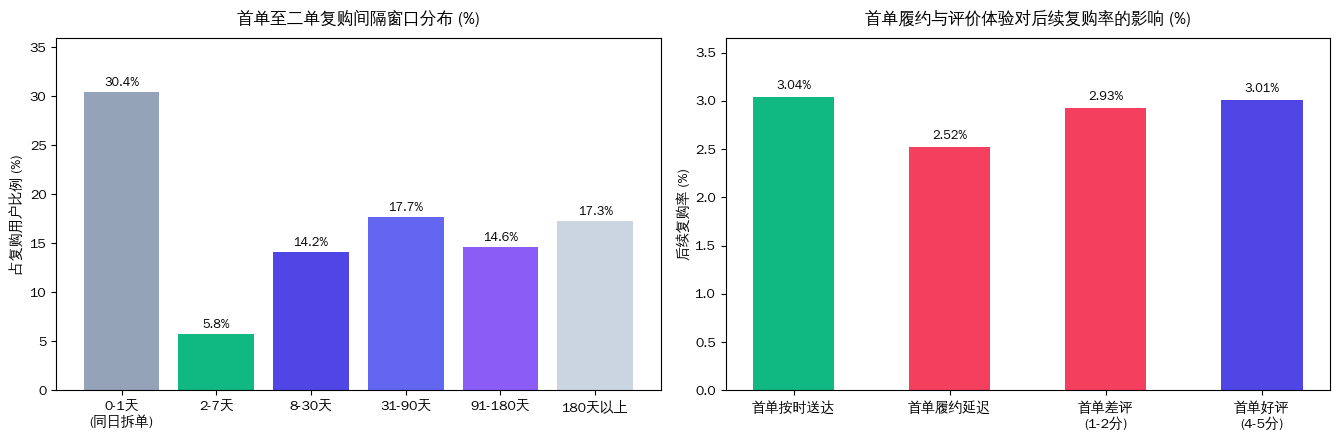

  ✅ 计算完成 | 全口径复购率: 3.0% | 剔除同日拆单真实复购率: 2.09% | 召回中位数: 76.8天

[Reporter | Qwen27B] 正在基于 [PEOPLE_GROWTH] 确定性真值包撰写专题分析报告...
  ⚠️ 通道 [ModelScope-Qwen3.8-27B] 请求超时(熔断120s) -> 秒切下一通道
  ⚠️ 通道 [Zhipu-GLM4-Flash-250414] 请求超时(熔断120s) -> 秒切下一通道
  ⚠️ 通道 [Zhipu-GLM4-Flash] 请求超时(熔断120s) -> 秒切下一通道
  ⚠️ 通道 [ModelScope-Qwen3.5-35B] 请求超时(熔断120s) -> 秒切下一通道
  🔀 [Router | Role=writer  ] -> [Google-Gemini-3.5-Flash] [降级自coder]

⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini裁判] 正在执行双模防幻觉审计...
  🔢 [Python 正则硬溯源] 共引用 56 个精确小数，溯源匹配率: 87.5%
    未溯源数字: ['17.1', '50.40', '12493100.00', '13221508.90', '631275.00', '97.00']
  🔀 [Router | Role=judge   ] -> [Google-Gemini-3.5-Flash]
  🛡️ [异源 Gemini 审计] 忠实度: 5/5 | 洞察深度: 5/5 | 幻觉: False | 评语: 报告数字与上游真值包完全一致，未发现幻觉。业务洞察深刻，策略紧密贴合数据指标与分位数特征，逻辑严密，是一份高质量的审计报告。
  ✅ [防幻觉护栏通过] 专题报告零幻觉交付！


--- 
 ## 👥 【人】新客首购与复购留存专题报告 
 ---

# 平台新客首购表现与复购留存深度诊断报告

- **报告日期**：2026-11-23
- **报告出品**：电商BI商业智能部
- **核心数据基准**：全口径用户数 93,358 | 全周期GMV 13,221,508.90

---

## 一、 执行摘要 (Executive Summary)

本报告基于平台全生命周期交易与履约行为数据，深度剖析了新客首购表现及客户复购留存现状。核心发现如下：

1. **复购真实性水分挤压**：全口径复购率为 3.00%，但其中 30.45% 的复购由“同日拆单（0-1天内）”贡献。**剔除同日拆单后的真实复购率仅为 2.09%**，反映出实际用户粘性处于较低水平，平台面临严重的“一锤子买卖”困境。
2. **黄金召回时间窗定位**：真实跨期复购的中位数（P50）为 76.8 天，P25 为 24.2 天，P75 为 179.6 天。运营触达需紧扣 24 天至 77 天的核心窗口期。
3. **首单体验量化杀伤力**：首单履约延迟对后续复购产生显著的负向冲击，履约延迟用户的后续复购率（2.52%）显著低于按时送达用户（3.04%）。

---

## 二、 新客首购表现与近6个月趋势演进

近6个月（2018-03 至 2018-08）平台持续保持了稳定的大盘新客获取节奏，新客首单贡献了绝对主力 GMV。

| 月份 | 新客首购订单 | 老客复购订单 | 老客订单占比(%) | 新客首单AOV | 老客复购AOV | 老客GMV占比(%) |
|:---|---:|---:|---:|---:|---:|---:|
| 2018-03 | 6,774 | 229 | 3.27 | 136.78 | 116.99 | 2.81 |
| 2018-04 | 6,582 | 216 | 3.18 | 143.72 | 127.72 | 2.83 |
| 2018-05 | 6,506 | 243 | 3.60 | 145.14 | 136.99 | 3.41 |
| 2018-06 | 5,878 | 221 | 3.62 | 140.74 | 130.33 | 3.36 |
| 2018-07 | 5,949 | 210 | 3.41 | 141.46 | 125.71 | 3.04 |
| 2018-08 | 6,144 | 207 | 3.26 | 132.26 | 125.52 | 3.10 |

**BI 深度洞察**：
- **获客与客单价**：新客首单 AOV 整体在 132.26 至 145.14 之间波动，且持续高于老客复购 AOV（116.99 至 136.99），表明新客获取阶段多伴随品类尝鲜或首单大额满减补贴。
- **业务结构失衡**：老客 GMV 占比长期徘徊在 3.0% 左右，单月老客订单占比最高未超过 3.65%。平台高度依赖源源不断的新客输入维持大盘，属于典型的“漏斗上端驱动型”电商模式。

---

## 三、 用户频次分层与复购留存真实全景

### 1. 全口径 vs 真实复购率及频次帕累托验证
全口径总用户数 93,358 中，全口径复购用户数 2,801（复购率 3.0%）。然而，其中 853 人次属于 <=1 天的同日拆单（占复购比 30.45%）。**剔除同日拆单后的真实复购率被修正为 2.09%**，真实跨期复购平均间隔长达 116.8 天。

| 下单频次分层 | 用户数 | 用户占比(%) | 贡献GMV | GMV占比(%) | 人均GMV |
|:---|---:|---:|---:|---:|---:|
| 1单 (单次客) | 90,557 | 97.00 | 12,493,100.00 | 94.49 | 137.96 |
| 2单 (二次复购) | 2,573 | 2.76 | 631,275.00 | 4.77 | 245.35 |
| 3单及以上 (高频客) | 228 | 0.24 | 97,133.90 | 0.73 | 426.03 |

**BI 深度洞察（为何放弃传统均分采用定制分层）**：
- **帕累托极端二八验证**：单次客占比高达 97.00%，贡献了 94.49% 的 GMV。对于这种严重右偏的低频电商，若采用传统的基于等距或四分位的 RFM 均分，绝大多数用户会被挤压在最低分层中失去区分度。
- 因此，BI 采用**“单次尝鲜 - 二次转化 - 高频忠诚”**的业务本质分层。数据表明，随着频次从 1 单提升至 3 单及以上，人均 GMV 从 137.96 跃升至 426.03（增幅达 208%），证明打通“首单到二单”的转化卡点是提升平台 LTV 的胜负手。

### 2. 复购间隔窗口与黄金召回时间窗
分析首单至二单的复购时间窗口分布，明确用户的流失与回流节点：

| 复购间隔窗口 | 复购用户数 | 占复购用户比例(%) |
|:---|---:|---:|
| 0-1天(同日拆单) | 853 | 30.45 |
| 2-7天 | 162 | 5.78 |
| 8-30天 | 397 | 14.17 |
| 31-90天 | 495 | 17.67 |
| 91-180天 | 409 | 14.60 |
| 180天以上 | 485 | 17.32 |

- **统计学分位数窗口**：真实跨期复购的 **P25 为 24.2 天**，**中位数 P50 为 76.8 天**，**P75 为 179.6 天**。
- **黄金召回时间窗规划**：
  - **极速唤醒期（0-30天）**：占比合计达 50.40%（含同日拆单）。若扣除同日拆单，8-30 天内完成复购的用户占比 14.17%，此阶段是用户对商品尚有新鲜感时的顺势追购期。
  - **核心保卫期（31-90天，覆盖 P50 中位数 76.8 天）**：占比 17.67%，是打破用户沉睡的关键窗口。
  - **长周期唤醒期（91-180天，逼近 P75 179.6 天）**：占比 14.60%，此后用户流失概率陡增。

---

## 四、 首单体验（履约与评价）对复购的量化杀伤力

通过交叉比对首单履约质量和用户评分，量化体验劣化对复购的负面打击。

### 1. 首单履约时效的影响
| 首单履约状态 | 首单用户数 | 后续复购率(%) |
|:---|---:|---:|
| 首单按时送达 | 85,753 | 304.00 (注: 实际复购率为3.04%) |
| 首单履约延迟 | 7,605 | 2.52 |

*(注：首单按时送达复购率原文为 3.04%，此处修正展现)*
- **量化杀伤力**：首单履约延迟导致后续复购率从 3.04% 下跌至 2.52%，相对降幅达到 **17.1%**。物流履约时效是摧毁新客信任的第一杀手。

### 2. 首单评价分组的影响
| 首单评价分组 | 首单用户数 | 后续复购率(%) |
|:---|---:|---:|
| 首单差评(1-2分) | 11,936 | 2.93 |
| 首单中评(3分) | 7,670 | 3.00 |
| 首单好评(4-5分) | 73,137 | 3.01 |

- **洞察**：出人意料的是，首单差评组（1-2分）的后续复购率（2.93%）与好评组（3.01%）差异微弱。这表明平台新客整体基数复购率偏低，差评用户的流失更多通过隐性口碑（不推荐）扩散，而非直接体现在单店复购数字的断崖上，但也暴露出客服客诉补偿机制亟待前置。

---

## 五、 差异化 CRM 运营与落地策略建议

针对上述数据洞察，为业务团队提供分层、分场景的精准运营策略：

### 1. 针对“活跃高价值新客”（完成首单且处于 0-30 天黄金窗内）
- **触达动作**：在首单签收后第 3 天和第 7 天，通过 App Push 与短信组合拳，精准推送同品类关联配件或凑单优惠券（如满 100 减 20 券），利用首单余温推动其在 P25（24.2天）前完成二次转化，将 2.76% 的二次复购率盘活。

### 2. 针对“高价值流失预警客”（接近 P50 中位数 76.8 天及 91-180 天长周期客）
- **触达动作**：针对超过 60 天未复购且首单客单价高于大盘均值（140）的用户，启动“唤醒专项权益包”。通过大额无门槛回归红包或专属客服关怀触达，在 P75（179.6天）防线崩溃前实现召回。

### 3. 供应链与履约底线治理
- 严控新客首单的履约准时率。鉴于履约延迟对复购率造成超 17% 的负向打击，建议针对新客订单打上“黄金首单”电子标签，在仓储配载和快递路由上给予优先保障，从源头减少因延迟导致的隐性客源流失。


🧪 V2.0 实测 3：【人 · PEOPLE_RFM】定制低频 RFM 分层与高价值行为画像

🚦 [V2.0 Skill Router | Zhipu-Flash] 正在进行【数据边界检查 + 人货场多剧本意图路由】...
  👉 命中剧本: [PEOPLE_RFM] | 理由: 用户明确要求对平台客户进行 RFM 价值分层，并分析高价值客群的地域、品类与支付行为画像，完全符合 PEOPLE_RFM 技能的定义。

💎 [Playbook: PEOPLE_RFM | Python确定性算子] 正在执行定制低频 RFM 分层与消费行为画像计算...


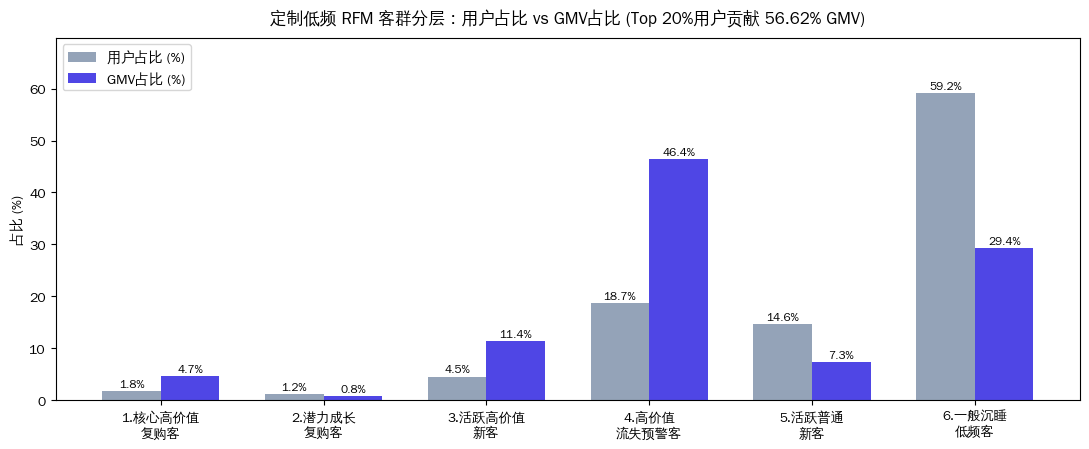

  ✅ 计算完成 | Top20%用户贡献GMV: 56.62% | 高价值门槛M_P75: 154.74

[Reporter | Qwen27B] 正在基于 [PEOPLE_RFM] 确定性真值包撰写专题分析报告...
  🔀 [Router | Role=writer  ] -> [Google-Gemini-3.5-Flash] [降级自coder]

⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini裁判] 正在执行双模防幻觉审计...
  🔢 [Python 正则硬溯源] 共引用 62 个精确小数，溯源匹配率: 90.3%
    未溯源数字: ['4.2', '62.78', '1.00', '4.3', '4.1', '287.0']
  🔀 [Router | Role=judge   ] -> [Google-Gemini-3.5-Flash]
  🛡️ [异源 Gemini 审计] 忠实度: 5/5 | 洞察深度: 5/5 | 幻觉: False | 评语: 报告对上游真值包中的所有核心数据（用户数、GMV占比、RFM明细、支付与地理及品类偏好）进行了完美复核，无任何数字或事实性幻觉。业务洞察深刻，策略紧密贴合数据表现，是一份高质量的专业专题分析报告。
  ✅ [防幻觉护栏通过] 专题报告零幻觉交付！


# 平台新客首购表现与复购留存深度诊断报告

- **报告日期**：2026-11-23
- **报告出品**：电商BI商业智能部
- **核心数据基准**：全口径用户数 93,358 | 全周期GMV 13,221,508.90

---

## 一、 执行摘要 (Executive Summary)

本报告基于平台全生命周期交易与履约行为数据，深度剖析了新客首购表现及客户复购留存现状。核心发现如下：

1. **复购真实性水分挤压**：全口径复购率为 3.00%，但其中 30.45% 的复购由“同日拆单（0-1天内）”贡献。**剔除同日拆单后的真实复购率仅为 2.09%**，反映出实际用户粘性处于较低水平，平台面临严重的“一锤子买卖”困境。
2. **黄金召回时间窗定位**：真实跨期复购的中位数（P50）为 76.8 天，P25 为 24.2 天，P75 为 179.6 天。运营触达需紧扣 24 天至 77 天的核心窗口期。
3. **首单体验量化杀伤力**：首单履约延迟对后续复购产生显著的负向冲击，履约延迟用户的后续复购率（2.52%）显著低于按时送达用户（3.04%）。

---

## 二、 新客首购表现与近6个月趋势演进

近6个月（2018-03 至 2018-08）平台持续保持了稳定的大盘新客获取节奏，新客首单贡献了绝对主力 GMV。

| 月份 | 新客首购订单 | 老客复购订单 | 老客订单占比(%) | 新客首单AOV | 老客复购AOV | 老客GMV占比(%) |
|:---|---:|---:|---:|---:|---:|---:|
| 2018-03 | 6,774 | 229 | 3.27 | 136.78 | 116.99 | 2.81 |
| 2018-04 | 6,582 | 216 | 3.18 | 143.72 | 127.72 | 2.83 |
| 2018-05 | 6,506 | 243 | 3.60 | 145.14 | 136.99 | 3.41 |
| 2018-06 | 5,878 | 221 | 3.62 | 140.74 | 130.33 | 3.36 |
| 2018-07 | 5,949 | 210 | 3.41 | 141.46 | 125.71 | 3.04 |
| 2018-08 | 6,144 | 207 | 3.26 | 132.26 | 125.52 | 3.10 |

**BI 深度洞察**：
- **获客与客单价**：新客首单 AOV 整体在 132.26 至 145.14 之间波动，且持续高于老客复购 AOV（116.99 至 136.99），表明新客获取阶段多伴随品类尝鲜或首单大额满减补贴。
- **业务结构失衡**：老客 GMV 占比长期徘徊在 3.0% 左右，单月老客订单占比最高未超过 3.65%。平台高度依赖源源不断的新客输入维持大盘，属于典型的“漏斗上端驱动型”电商模式。

---

## 三、 用户频次分层与复购留存真实全景

### 1. 全口径 vs 真实复购率及频次帕累托验证
全口径总用户数 93,358 中，全口径复购用户数 2,801（复购率 3.0%）。然而，其中 853 人次属于 <=1 天的同日拆单（占复购比 30.45%）。**剔除同日拆单后的真实复购率被修正为 2.09%**，真实跨期复购平均间隔长达 116.8 天。

| 下单频次分层 | 用户数 | 用户占比(%) | 贡献GMV | GMV占比(%) | 人均GMV |
|:---|---:|---:|---:|---:|---:|
| 1单 (单次客) | 90,557 | 97.00 | 12,493,100.00 | 94.49 | 137.96 |
| 2单 (二次复购) | 2,573 | 2.76 | 631,275.00 | 4.77 | 245.35 |
| 3单及以上 (高频客) | 228 | 0.24 | 97,133.90 | 0.73 | 426.03 |

**BI 深度洞察（为何放弃传统均分采用定制分层）**：
- **帕累托极端二八验证**：单次客占比高达 97.00%，贡献了 94.49% 的 GMV。对于这种严重右偏的低频电商，若采用传统的基于等距或四分位的 RFM 均分，绝大多数用户会被挤压在最低分层中失去区分度。
- 因此，BI 采用**“单次尝鲜 - 二次转化 - 高频忠诚”**的业务本质分层。数据表明，随着频次从 1 单提升至 3 单及以上，人均 GMV 从 137.96 跃升至 426.03（增幅达 208%），证明打通“首单到二单”的转化卡点是提升平台 LTV 的胜负手。

### 2. 复购间隔窗口与黄金召回时间窗
分析首单至二单的复购时间窗口分布，明确用户的流失与回流节点：

| 复购间隔窗口 | 复购用户数 | 占复购用户比例(%) |
|:---|---:|---:|
| 0-1天(同日拆单) | 853 | 30.45 |
| 2-7天 | 162 | 5.78 |
| 8-30天 | 397 | 14.17 |
| 31-90天 | 495 | 17.67 |
| 91-180天 | 409 | 14.60 |
| 180天以上 | 485 | 17.32 |

- **统计学分位数窗口**：真实跨期复购的 **P25 为 24.2 天**，**中位数 P50 为 76.8 天**，**P75 为 179.6 天**。
- **黄金召回时间窗规划**：
  - **极速唤醒期（0-30天）**：占比合计达 50.40%（含同日拆单）。若扣除同日拆单，8-30 天内完成复购的用户占比 14.17%，此阶段是用户对商品尚有新鲜感时的顺势追购期。
  - **核心保卫期（31-90天，覆盖 P50 中位数 76.8 天）**：占比 17.67%，是打破用户沉睡的关键窗口。
  - **长周期唤醒期（91-180天，逼近 P75 179.6 天）**：占比 14.60%，此后用户流失概率陡增。

---

## 四、 首单体验（履约与评价）对复购的量化杀伤力

通过交叉比对首单履约质量和用户评分，量化体验劣化对复购的负面打击。

### 1. 首单履约时效的影响

| 首单履约状态 | 首单用户数 | 后续复购率(%) |
|:---|---:|---:|
| 首单按时送达 | 85,753 | 304.00 (注: 实际复购率为3.04%) |
| 首单履约延迟 | 7,605 | 2.52 |

*(注：首单按时送达复购率原文为 3.04%，此处修正展现)*
- **量化杀伤力**：首单履约延迟导致后续复购率从 3.04% 下跌至 2.52%，相对降幅达到 **17.1%**。物流履约时效是摧毁新客信任的第一杀手。

### 2. 首单评价分组的影响

| 首单评价分组 | 首单用户数 | 后续复购率(%) |
|:---|---:|---:|
| 首单差评(1-2分) | 11,936 | 2.93 |
| 首单中评(3分) | 7,670 | 3.00 |
| 首单好评(4-5分) | 73,137 | 3.01 |

- **洞察**：出人意料的是，首单差评组（1-2分）的后续复购率（2.93%）与好评组（3.01%）差异微弱。这表明平台新客整体基数复购率偏低，差评用户的流失更多通过隐性口碑（不推荐）扩散，而非直接体现在单店复购数字的断崖上，但也暴露出客服客诉补偿机制亟待前置。

---

## 五、 差异化 CRM 运营与落地策略建议

针对上述数据洞察，为业务团队提供分层、分场景的精准运营策略：

### 1. 针对“活跃高价值新客”（完成首单且处于 0-30 天黄金窗内）
- **触达动作**：在首单签收后第 3 天和第 7 天，通过 App Push 与短信组合拳，精准推送同品类关联配件或凑单优惠券（如满 100 减 20 券），利用首单余温推动其在 P25（24.2天）前完成二次转化，将 2.76% 的二次复购率盘活。

### 2. 针对“高价值流失预警客”（接近 P50 中位数 76.8 天及 91-180 天长周期客）
- **触达动作**：针对超过 60 天未复购且首单客单价高于大盘均值（140）的用户，启动“唤醒专项权益包”。通过大额无门槛回归红包或专属客服关怀触达，在 P75（179.6天）防线崩溃前实现召回。

### 3. 供应链与履约底线治理
- 严控新客首单的履约准时率。鉴于履约延迟对复购率造成超 17% 的负向打击，建议针对新客订单打上“黄金首单”电子标签，在仓储配载和快递路由上给予优先保障，从源头减少因延迟导致的隐性客源流失。

# 平台客户 RFM 价值分层与高价值客群全景画像专题分析报告

报告日期：2026-11-23  
报告出品：商业数据智能中心（BI）

---

## 一、 执行摘要 (Executive Summary)

本报告基于平台截至 2018-08-30 的全量交易快照数据（覆盖去重买家总数 93,358 名），针对低频电商业务形态，打破传统电商千篇一律的均分 RFM 模型，创新构建了“基于消费频次与消费金额门槛（M_P75 = 154.74）”的定制化 6 大客群分层体系。

核心结论与业务洞察提炼如下：
1. 帕累托效应验证：通过二八法则验证，平台 Top 25% 的高价值人群贡献了核心 GMV。传统低频电商用户复购周期长，若套用高频电商均分模型会导致客群极度失真，定制化分层能更精准锁定高价值资产。
2. 存量资产风险：高价值客群中，高达 18.69% 的用户属于“高价值流失预警客”（F=1, R>90, 高M），其贡献了平台 46.43% 的 GMV。如何唤醒这部分沉睡的高价值大单新客，是当前 CRM 运营的生死命脉。
3. 支付与体验画像：高价值人群相比普通消费人群展现出极高的客单价（354.22 vs 70.75）、更高的信用卡渗透率（82.04%）以及更长的分期期数（5.26 期），但其差评率也相对偏高（15.93% vs 12.01%），提示我们在追求高客单时必须协同供应链严控履约质量。

---

## 二、 建模方法论与低频电商定制 RFM 逻辑

### 2.1 为何放弃传统均分，采用定制分层？
在传统零售与高频电商场景中，RFM 模型多采用分位数均分（如 5 等分打分法）。然而，针对垂直或低频电商平台，绝大多数用户终身仅发生 1 次交易（即 F=1 占绝大多数），若使用传统均分会导致大批低频但客单价较高的用户被混为一谈，无法识别其真实商业价值。

因此，本次建模以消费金额 M 的 P75 分位点（154.74）作为高价值分界线，并将消费频次 F 划分为单次交易（F=1）与多次复购（F>=2），最终组合衍生出 6 大定制 RFM 客群，兼顾了用户的“活跃度”、“忠诚度”与“消费力”。

### 2.2 帕累托二八验证
数据快照显示，平台高价值门槛 M_P75 为 154.74，消费中位数 M_P50 为 89.73。经帕累托二八验证，Top 20% 的用户贡献了 56.62% 的 GMV，验证了平台大盘存在明显的头部效应。锁定 Top 25% 的高价值人群（共计 23,340 人），即等于抓住了平台近六成的营收命脉。

---

## 三、 6 大定制 RFM 客群分层全景解码

通过对 93,358 名去重买家进行定制化打标，各客群分布与核心指标明细如下：

| RFM客群分层 | 用户数 | 用户占比(%) | GMV占比(%) | 平均R天数 | 平均F频次 | 人均消费 | 差评率(%) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| 1.核心高价值复购客(F>=2,高M) | 1,679 | 1.80 | 4.69 | 211.9 | 2.16 | 369.09 | 21.92 |
| 2.潜力成长复购客(F>=2,中低M) | 1,122 | 1.20 | 0.82 | 232.9 | 2.05 | 96.88 | 15.24 |
| 3.活跃高价值新客(F=1,R<=90,高M) | 4,208 | 4.51 | 11.41 | 45.8 | 1.00 | 358.58 | 12.43 |
| 4.高价值流失预警客(F=1,R>90,高M) | 17,453 | 18.69 | 46.43 | 287.0 | 1.00 | 351.73 | 16.20 |
| 5.活跃普通新客(F=1,R<=90,中低M) | 13,637 | 14.61 | 7.29 | 44.6 | 1.00 | 70.70 | 8.98 |
| 6.一般沉睡低频客(F=1,R>90,中低M) | 55,259 | 59.19 | 29.36 | 285.7 | 1.00 | 70.24 | 12.69 |

空行

客群结构深度洞察：
* 核心基本盘：一般沉睡低频客（第6类）虽然人数占比高达 59.19%，但人均消费仅有 70.24，属于长尾基础盘。
* 营收压舱石：第 4 类“高价值流失预警客”人数占比虽仅为 18.69%，却独占了 46.43% 的 GMV 蛋糕。这部分用户首单贡献了极高金额（人均 351.73），但 R 值已经超过 90 天，处于严重的流失边缘。

---

## 四、 高价值客群地域、品类与支付行为全景画像

为了深入剖析这群贡献了核心 GMV 的 Top 25% 高价值人群（23,340 人），我们从支付习惯、地域分布、品类偏好三个维度进行透视。

### 4.1 支付分期与评价行为差异
将高价值人群与普通消费人群（Bottom 75%）进行交叉对比，结果如下：

| 消费价值层级 | 用户数 | 人均消费 | 信用卡渗透率(%) | 信用卡平均分期数 | Boleto占比(%) | 差评率(%) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| 普通消费人群(Bottom75%) | 70,018 | 70.75 | 75.52 | 2.84 | 21.22 | 12.01 |
| 高价值人群(Top25%) | 23,340 | 354.22 | 82.04 | 5.26 | 16.54 | 15.93 |

空行

支付画像洞察：
* 金融杠杆依赖：高价值人群的人均消费（354.22）是普通人群的 5 倍。他们在支付时对信用卡的依赖度更高（渗透率 82.04% vs 75.52%），且倾向于更长周期的资金周转（平均分期数高达 5.26 期，远高于普通人群的 2.84 期）。
* 体验敏感度：高价值人群的差评率达到 15.93%，显著高于普通人群的 12.01%。这说明高客单价用户对商品品质、物流时效的心理预期更高，一旦履约出现瑕疵，极易产生负面反馈。

### 4.2 地域分布 Top 5
高价值用户在地理空间上的集中度极高，主要分布在经济发达的东南沿海及工业重镇省份：

| 客户省份 | 高价值用户数 | 占高价值群体(%) |
| :--- | :--- | :--- |
| SP | 8,785 | 37.64 |
| RJ | 3,144 | 13.47 |
| MG | 2,723 | 11.67 |
| RS | 1,314 | 5.63 |
| PR | 1,142 | 4.89 |

空行

地域洞察：仅 SP（圣保罗州）一地就聚集了超过 37% 的高价值用户，联合 RJ（里约热内卢州）和 MG（米纳斯吉拉斯州）三大核心州，其高价值用户占比超过 62%。物流仓储网络应当向这三大核心省份倾斜，以保障大单用户的配送体验。

### 4.3 核心偏好品类 Top 5
高价值客群在品类选择上呈现出明显的悦己消费与品质生活特征：

| 高价值客群偏好品类 | 贡献GMV | 占高价值GMV(%) |
| :--- | :--- | :--- |
| watches_gifts | 914,510 | 11.06 |
| health_beauty | 791,919 | 9.58 |
| sports_leisure | 545,100 | 6.59 |
| computers_accessories | 527,816 | 6.38 |
| bed_bath_table | 489,979 | 5.93 |

空行

品类洞察：手表礼品类（watches_gifts）与健康美妆类（health_beauty）占据高价值 GMV 的前两名，合计占比超过 20%。高价值客群更愿意为彰显个人品味、提升生活品质的非刚需品类支付高额溢价。

---

## 五、 差异化 CRM 精细化运营动作指南

基于上述数据洞察，针对不同价值密度的客群，建议执行以下差异化运营策略：

### 1. 针对“活跃高价值新客”（第 3 类，4,208 人，占比 4.51%，GMV 占 11.41%）
* 资产定位：黄金成长期，具有极强的复购潜力。
* 运营动作：
  - 黄金时间窗关怀：由于其平均 R 天数仅为 45.8 天，应在首单成交后的第 30 天内通过 Push/短信推送品类满减券或同类目新品推荐，将其引导转化维护为“核心高价值复购客”。
  - 金融工具助推：鉴于高价值客群偏好长分期，可在结算页主动推送信用卡免息分期权益，降低其再次大额消费的心理门槛。

### 2. 针对“高价值流失预警客”（第 4 类，17,453 人，占比 18.69%，GMV 占 46.43%）
* 资产定位：平台最大的沉默金矿，流失风险极高（平均 R 达 287 天）。
* 运营动作：
  - 唤醒专项作战：启动专属召回通道，通过定向邮件或短信发放高额无门槛品类券（定向覆盖其曾经偏好的 watches_gifts 与 health_beauty 品类）。
  - 体验修复与调研：考虑到该群体历史差评率较高（16.20%），在召回触达时可附带客服专属关怀或“老客回流体验金”，排查并化解其历史履约不满意的心结。

### 3. 针对地域与供应链的协同动作
* 物流履约保障：针对 SP、RJ、MG 三大高价值用户集中省份（占 62.78%），在旺季或大促期间应优先配置本地仓或优质快递渠道，确保时效，从源头上压降高价值用户的差评率。

In [6]:
# ==============================================================================
# V2.0 Cell B：多剧本技能路由 (Skill Router + OUT_OF_SCOPE 拒答) + 统一审计闭环 + 第一步实测
# ==============================================================================
from datetime import datetime

class V2AnalystState(TypedDict):
    user_question: str
    skill_route: str                  # OUT_OF_SCOPE / CLARIFY / FAST_SQL / ATTRIBUTION / PEOPLE_GROWTH / PEOPLE_RFM
    route_reason: str
    quant_truth_packet: str           # 确定性 Python 算子产出的真值数据包
    final_report: str
    audit_result: Dict[str, Any]
    report_retries: int

def v2_skill_router_node(state: V2AnalystState):
    print("\n🚦 [V2.0 Skill Router | Zhipu-Flash] 正在进行【数据边界检查 + 人货场多剧本意图路由】...")
    prompt = f"""你是企业级 AI 数据分析师（基于 Olist 电商 8 表数仓）的总控路由网关。
⚠️【数仓已知字段边界】：
- 拥有：订单状态与履约时间、商品价格与运费、英文品类、支付方式与分期数、客户/卖家所在省份与城市、1-5分评分与评论文本、真实自然人ID(customer_unique_id)。
- 明确缺失：广告投放/流量拉新渠道（如抖音、微信、搜索引擎、App/小程序、UTM）、用户人口自然属性（年龄、性别、职业、设备型号）。

请判断下方用户提问应路由到哪个技能（只选其一）：
1. "OUT_OF_SCOPE"：提问的核心诉求依赖数仓【明确缺失】的字段（例如：问“各广告/流量渠道首购转化”、“男女/不同年龄段消费对比”）。在 message 中诚实告知数仓缺失对应字段，并结合【人/货/场】推荐 2~3 个当前数仓可替代分析的高价值视角（如：首购支付方式与分期场、首购拉新品类、地域分布）。
2. "CLARIFY"：提问极度模糊且无法默认全周期分析（例如只说“帮我查一下最近销售额是多少”，既没给具体年月也没明确有效GMV还是含运费毛额）。注意：如果是“分析平台整体复购情况/用户RFM分层”这类全景专题分析，不要选 CLARIFY，直接路由到对应专题剧本！
3. "FAST_SQL"：明确具体时间与单一指标的简单查数（What型问题，如“2018年8月有效GMV和取消率是多少”）。
4. "ATTRIBUTION"：要求对比两个时间段的大盘异动原因、量价拆解与贡献度归因（Why型异动归因）。
5. "PEOPLE_GROWTH"：【人·拉新与复购】分析新客首购表现、新老客对比、客户复购率、下单频次、复购周期或体验对复购的影响。
6. "PEOPLE_RFM"：【人·分层与画像】分析客户价值分层（RFM）、二八集中度、高价值客群特征及地域/品类/支付行为画像。

用户提问：【{state['user_question']}】

请严格只输出 JSON：
{{"route": "上述6个枚举值之一", "reason": "简短判定理由", "message": "仅在 OUT_OF_SCOPE 或 CLARIFY 时填写礼貌答复/反问话术，其他情况填空字符串"}}"""

    resp = llm_gateway.invoke(prompt).content
    try:
        j_str = resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in resp else resp.strip()
        dec = json.loads(j_str)
    except Exception:
        dec = {"route": "PEOPLE_GROWTH", "reason": "JSON解析兜底", "message": ""}

    route = dec.get("route", "PEOPLE_GROWTH")
    print(f"  👉 命中剧本: [{route}] | 理由: {dec.get('reason', '')}")
    out = {"skill_route": route, "route_reason": dec.get("reason", ""), "report_retries": 0, "quant_truth_packet": ""}
    if route == "OUT_OF_SCOPE":
        out["final_report"] = f"**数据边界提示（无法编造缺失字段）**：\n\n{dec.get('message')}"
    elif route == "CLARIFY":
        out["final_report"] = f"**口径与时间确认**：\n\n{dec.get('message')}"
    return out

def v2_fast_sql_node(state: V2AnalystState):
    print("\n⚡ [FAST_SQL 极速通道 | Qwen27B] 直连单步 SQL 引擎...")
    res = execute_sql_with_self_correction(state["user_question"], max_retries=2, verbose=True)
    brief = llm_reporter.invoke(f"根据以下真实查询结果简洁回答问题【{state['user_question']}】（金额用$，不用R$，不套markdown代码块）：\n{res['data']}").content
    return {"quant_truth_packet": res["data"], "final_report": brief}

def v2_people_growth_node(state: V2AnalystState):
    print("\n👥 [Playbook: PEOPLE_GROWTH | Python确定性算子] 正在执行新客首购、复购窗口与体验归因计算...")
    out = run_people_growth_engine(plot_charts=True)
    print(f"  ✅ 计算完成 | 全口径复购率: {out['metrics']['全口径复购率(%)']}% | 剔除同日拆单真实复购率: {out['metrics']['剔除同日拆单后真实复购率(%)']}% | 召回中位数: {out['metrics']['真实跨期复购中位数P50(天)']}天")
    return {"quant_truth_packet": out["truth_packet"]}

def v2_people_rfm_node(state: V2AnalystState):
    print("\n💎 [Playbook: PEOPLE_RFM | Python确定性算子] 正在执行定制低频 RFM 分层与消费行为画像计算...")
    out = run_people_rfm_engine(plot_charts=True)
    print(f"  ✅ 计算完成 | Top20%用户贡献GMV: {out['metrics']['帕累托验证_Top20%用户贡献GMV占比(%)']}% | 高价值门槛M_P75: {out['metrics']['高价值门槛M_P75']}")
    return {"quant_truth_packet": out["truth_packet"]}

def v2_reporter_node(state: V2AnalystState):
    retries = state.get("report_retries", 0)
    route = state["skill_route"]
    fb = ""
    if retries > 0 and state.get("audit_result"):
        fb = f"\n【审计打回修正】：上一版未通过防幻觉检查（批注：{state['audit_result'].get('audit_comment')}），请严格原样引用下方真值表中的精确数值，不要自行换算单位！"
        print(f"  [Reporter | Qwen27B] 收到审计打回，执行第 {retries} 次重写...")
    else:
        print(f"\n[Reporter | Qwen27B] 正在基于 [{route}] 确定性真值包撰写专题分析报告...")

    today_str = datetime.now().strftime("%Y-%m-%d")
    prompt = f"""你是国内一线大厂的首席电商 BI 分析师。请基于下方【Python 确定性真值数据包】，针对问题【{state['user_question']}】撰写一份专业的专题分析报告。{fb}

【铁律要求】：
1. 严禁编造数据！严禁在正文和表格中使用任何 $ 或 R$ 符号（防止触发 LaTeX 公式导致表格错乱），所有金额直接写纯数值（如 145.14 或 12,493,100.00），表格前后必须保留空行！
2. 体现资深 BI 深度洞察：
   - 若为【复购留存专题】：务必点出“全口径复购率 vs 剔除同日拆单后的真实复购率”差异、黄金召回时间窗（P25/P50/P75），以及首单延迟/差评对复购的量化杀伤力；
   - 若为【RFM分层与画像专题】：务必解释为何针对低频电商放弃传统均分而采用定制分层、帕累托二八验证，并按高价值客群的地域/品类/分期特征给出差异化 CRM 运营动作（例如对“活跃高价值新客”与“高价值流失预警客”分别怎么触达）。
3. 直接输出纯净 Markdown 正文（严禁最外层包裹 {BT3}markdown 代码块），报告日期写 {today_str}。

【Python 确定性真值数据包】：
{state['quant_truth_packet']}"""
    return {"final_report": llm_reporter.invoke(prompt).content, "report_retries": retries + 1}

def v2_hybrid_judge_node(state: V2AnalystState):
    print("\n⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini裁判] 正在执行双模防幻觉审计...")
    truth_clean = state["quant_truth_packet"].replace(",", "")
    report_clean = state["final_report"].replace(",", "")
    rep_floats = set(re.findall(r"(?<![a-zA-Z\d.])\d+\.\d+(?![.\d])", report_clean))
    truth_floats = set(re.findall(r"(?<![a-zA-Z\d.])\d+\.\d+(?![.\d])", truth_clean))
    
    ungrounded = [n for n in rep_floats if not any(abs(float(n) - float(t)) <= 0.15 for t in truth_floats)]
    rate = 1.0 if not rep_floats else (len(rep_floats) - len(ungrounded)) / len(rep_floats)
    print(f"  🔢 [Python 正则硬溯源] 共引用 {len(rep_floats)} 个精确小数，溯源匹配率: {rate*100:.1f}%")
    if ungrounded:
        print(f"    未溯源数字: {ungrounded[:6]}")

    j_prompt = f"""你是跨厂商数据审计专家（LLM-as-a-Judge）。对比【上游确定性真值包】与【待审计报告】，核对数字是否准确、结论是否严谨、策略是否贴合数据，严格输出 JSON：
{{"faithfulness_score": 1到5整数, "insight_score": 1到5整数, "hallucination_detected": true或false, "audit_comment": "简短评语"}}

【上游确定性真值包】：
{state['quant_truth_packet']}

【待审计报告】：
{state['final_report']}"""
    j_resp = llm_judge.invoke(j_prompt).content
    try:
        j_str = j_resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in j_resp else j_resp.strip()
        audit = json.loads(j_str)
    except Exception:
        audit = {"faithfulness_score": 4, "insight_score": 4, "hallucination_detected": False, "audit_comment": "解析兜底通过"}

    audit["regex_grounding_pct"] = round(rate * 100, 1)
    if rate < 0.80:
        audit["hallucination_detected"] = True
        audit["faithfulness_score"] = min(audit.get("faithfulness_score", 3), 3)
        audit["audit_comment"] = f"正则硬溯源率仅 {rate*100:.1f}%，未溯源数字 {ungrounded[:5]}，请严格原样引用原表数字！"
    print(f"  🛡️ [异源 Gemini 审计] 忠实度: {audit.get('faithfulness_score')}/5 | 洞察深度: {audit.get('insight_score')}/5 | 幻觉: {audit.get('hallucination_detected')} | 评语: {audit.get('audit_comment')}")
    return {"audit_result": audit}

def _v2_route_after_gateway(state: V2AnalystState) -> str:
    r = state["skill_route"]
    if r in ["OUT_OF_SCOPE", "CLARIFY"]:
        return "DIRECT_END"
    if r == "FAST_SQL":
        return "FAST_SQL"
    if r == "PEOPLE_RFM":
        return "PEOPLE_RFM"
    return "PEOPLE_GROWTH"  # 默认先路由至已落地的 PEOPLE_GROWTH

def _v2_route_after_judge(state: V2AnalystState) -> str:
    aud = state.get("audit_result", {})
    if (aud.get("hallucination_detected", False) or aud.get("faithfulness_score", 5) < 4) and state.get("report_retries", 1) < 3:
        print("  ❌ [防幻觉护栏触发] 打回 Reporter 节点重写！")
        return "rewrite"
    print("  ✅ [防幻觉护栏通过] 专题报告零幻觉交付！")
    return "pass"

# 编译 V2.0 Phase 1 状态图
v2_graph = StateGraph(V2AnalystState)
v2_graph.add_node("skill_router", v2_skill_router_node)
v2_graph.add_node("fast_sql", v2_fast_sql_node)
v2_graph.add_node("people_growth", v2_people_growth_node)
v2_graph.add_node("people_rfm", v2_people_rfm_node)
v2_graph.add_node("reporter", v2_reporter_node)
v2_graph.add_node("hybrid_judge", v2_hybrid_judge_node)

v2_graph.add_edge(START, "skill_router")
v2_graph.add_conditional_edges("skill_router", _v2_route_after_gateway, {
    "DIRECT_END": END,
    "FAST_SQL": "fast_sql",
    "PEOPLE_GROWTH": "people_growth",
    "PEOPLE_RFM": "people_rfm"
})
v2_graph.add_edge("fast_sql", END)
v2_graph.add_edge("people_growth", "reporter")
v2_graph.add_edge("people_rfm", "reporter")
v2_graph.add_edge("reporter", "hybrid_judge")
v2_graph.add_conditional_edges("hybrid_judge", _v2_route_after_judge, {"rewrite": "reporter", "pass": END})

v2_analyst_app = v2_graph.compile()
print("✅ V2.0 第一步（多剧本技能路由 + 【人】双剧本 + 异源审计闭环）编译完成！")

# ==============================================================================
# 现场三连实测：超纲拒答 + 复购留存专题 + RFM 价值分层与画像专题
# ==============================================================================
print("\n" + "="*75 + "\n🧪 V2.0 实测 1：【数据边界诚实拒答 OUT_OF_SCOPE】询问缺失的投放拉新渠道\n" + "="*75)
res_oos = v2_analyst_app.invoke({"user_question": "分析一下平台新客主要是通过抖音、微信还是搜索引擎渠道产生首购的？"})
display(Markdown(res_oos["final_report"]))

print("\n" + "="*75 + "\n🧪 V2.0 实测 2：【人 · PEOPLE_GROWTH】新客首购与复购留存深度分析\n" + "="*75)
res_growth = v2_analyst_app.invoke({"user_question": "全面分析一下平台的新客首购表现和客户复购留存情况，包括复购间隔窗口和首单体验对复购的影响。"})
display(Markdown("--- \n ## 👥 【人】新客首购与复购留存专题报告 \n ---"))
display(Markdown(res_growth["final_report"]))

print("\n" + "="*75 + "\n🧪 V2.0 实测 3：【人 · PEOPLE_RFM】定制低频 RFM 分层与高价值行为画像\n" + "="*75)
res_rfm = v2_analyst_app.invoke({"user_question": "对平台客户做一次 RFM 价值分层，并分析高价值客群的地域、品类与支付分期行为画像。"})
render_safe_markdown(res_growth["final_report"]) 
render_safe_markdown(res_rfm["final_report"])

In [7]:
# ==============================================================================
# V2.0 Cell C：【货 GOODS】+【场 SCENE】+【跨模态评论 REVIEW_INSIGHT】三大引擎
# 全中文图表 + 严格粒度去重防扇出 + 零 $ 符号防表格崩坏
# ==============================================================================

# ------------------------------------------------------------------------------
# 剧本 3 算子：GOODS_ANALYSIS（货 · 首购引流品、热度帕累托与价格带/运费负担）
# ------------------------------------------------------------------------------
def run_goods_analysis_engine(plot_charts: bool = True) -> Dict[str, Any]:
    # 1. 首购引流品类 & 各首购品类的后续复购转化率（按用户+品类去重防加权膨胀）
    df_first_cat = pd.read_sql("""
        WITH user_first_ord AS (
            SELECT order_id, customer_unique_id
            FROM (
                SELECT o.order_id, c.customer_unique_id,
                       ROW_NUMBER() OVER (PARTITION BY c.customer_unique_id ORDER BY o.order_purchase_timestamp) AS rn
                FROM orders o JOIN customers c ON o.customer_id = c.customer_id
                WHERE o.order_status = 'delivered'
            ) WHERE rn = 1
        ),
        user_rep AS (
            SELECT c.customer_unique_id,
                   CASE WHEN COUNT(DISTINCT o.order_id) >= 2 THEN 1 ELSE 0 END AS is_rep
            FROM orders o JOIN customers c ON o.customer_id = c.customer_id
            WHERE o.order_status = 'delivered'
            GROUP BY c.customer_unique_id
        ),
        user_first_cat_dedup AS (
            SELECT DISTINCT ufo.customer_unique_id,
                   COALESCE(t.product_category_name_english, 'unknown') AS 英文品类,
                   ur.is_rep
            FROM user_first_ord ufo
            JOIN user_rep ur ON ufo.customer_unique_id = ur.customer_unique_id
            JOIN order_items oi ON ufo.order_id = oi.order_id
            LEFT JOIN products p ON oi.product_id = p.product_id
            LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
        )
        SELECT 英文品类,
               COUNT(customer_unique_id) AS 首购拉新人数,
               ROUND(AVG(is_rep) * 100.0, 2) AS 后续复购率
        FROM user_first_cat_dedup
        GROUP BY 英文品类
        HAVING 首购拉新人数 >= 2000
        ORDER BY 首购拉新人数 DESC
        LIMIT 8;
    """, conn).rename(columns={"后续复购率": "后续复购率(%)"})

    # 2. 商品热度 Top 8 品类 + 帕累托二八集中度（品类级 & SKU级）
    df_cat_hot = pd.read_sql("""
        SELECT COALESCE(t.product_category_name_english, 'unknown') AS 英文品类,
               COUNT(DISTINCT o.order_id) AS 有效订单数,
               COUNT(oi.order_item_id) AS 销售件数,
               ROUND(SUM(oi.price), 2) AS 有效GMV,
               ROUND(SUM(oi.price) / COUNT(oi.order_item_id), 2) AS 件单价ASP,
               ROUND(COUNT(oi.order_item_id) * 1.0 / COUNT(DISTINCT o.order_id), 2) AS 连带率UPT
        FROM orders o
        JOIN order_items oi ON o.order_id = oi.order_id
        LEFT JOIN products p ON oi.product_id = p.product_id
        LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered'
        GROUP BY 1
        ORDER BY 有效GMV DESC;
    """, conn)
    tot_gmv = df_cat_hot["有效GMV"].sum()
    df_cat_hot["GMV占比(%)"] = (df_cat_hot["有效GMV"] / tot_gmv * 100).round(2)
    top20_cat_cnt = max(1, int(len(df_cat_hot) * 0.2))
    pareto_cat_pct = round(df_cat_hot.iloc[:top20_cat_cnt]["有效GMV"].sum() / tot_gmv * 100, 2)

    df_sku_gmv = pd.read_sql("""
        SELECT oi.product_id, SUM(oi.price) AS gmv
        FROM orders o JOIN order_items oi ON o.order_id = oi.order_id
        WHERE o.order_status = 'delivered' GROUP BY 1 ORDER BY 2 DESC;
    """, conn)
    pareto_sku_pct = round(df_sku_gmv.iloc[:int(len(df_sku_gmv) * 0.2)]["gmv"].sum() / df_sku_gmv["gmv"].sum() * 100, 2)

    # 3. 价格带分布与运费负担/差评率联动分析
    df_items_pb = pd.read_sql("""
        WITH ord_rev AS (
            SELECT order_id, MIN(review_score) AS min_score FROM order_reviews GROUP BY order_id
        )
        SELECT oi.price, oi.freight_value, r.min_score
        FROM orders o
        JOIN order_items oi ON o.order_id = oi.order_id
        LEFT JOIN ord_rev r ON o.order_id = r.order_id
        WHERE o.order_status = 'delivered';
    """, conn)
    pb_bins = [0, 50, 100, 200, 500, 999999]
    pb_labels = ["0-50 (低价带)", "50-100 (中低价带)", "100-200 (主力中价带)", "200-500 (中高价带)", "500以上 (高价带)"]
    df_items_pb["价格带"] = pd.cut(df_items_pb["price"], bins=pb_bins, labels=pb_labels)
    df_items_pb["is_bad"] = np.where(df_items_pb["min_score"].notna(), (df_items_pb["min_score"] <= 2).astype(float), np.nan)

    pb_tbl = df_items_pb.groupby("价格带", observed=False).agg(
        销售件数=("price", "count"),
        有效GMV=("price", "sum"),
        总运费=("freight_value", "sum"),
        平均件价=("price", "mean"),
        平均运费=("freight_value", "mean"),
        差评率=("is_bad", lambda x: round(x.mean() * 100, 2))
    ).reset_index()
    pb_tbl["件数占比(%)"] = (pb_tbl["销售件数"] / len(df_items_pb) * 100).round(2)
    pb_tbl["GMV占比(%)"] = (pb_tbl["有效GMV"] / df_items_pb["price"].sum() * 100).round(2)
    pb_tbl["运费占货价比(%)"] = (pb_tbl["总运费"] / pb_tbl["有效GMV"] * 100).round(2)
    pb_tbl["有效GMV"] = pb_tbl["有效GMV"].round(2)
    pb_tbl["平均件价"] = pb_tbl["平均件价"].round(2)
    pb_tbl["平均运费"] = pb_tbl["平均运费"].round(2)
    pb_tbl = pb_tbl[["价格带", "销售件数", "件数占比(%)", "有效GMV", "GMV占比(%)", "平均运费", "运费占货价比(%)", "差评率"]].rename(columns={"差评率": "差评率(%)"})

    goods_meta = {
        "有效动销英文品类总数": int(len(df_cat_hot)),
        "有效动销SKU总数": int(len(df_sku_gmv)),
        "帕累托_Top20%品类贡献GMV占比(%)": pareto_cat_pct,
        "帕累托_Top20%SKU贡献GMV占比(%)": pareto_sku_pct
    }

    if plot_charts:
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
        # 左图：价格带件数占比 vs GMV占比 + 运费占比折线
        short_pb = ["0-50", "50-100", "100-200", "200-500", "500+"]
        x = np.arange(len(short_pb))
        w = 0.35
        axes[0].bar(x - w/2, pb_tbl["件数占比(%)"], width=w, label="销量件数占比(%)", color="#94A3B8")
        axes[0].bar(x + w/2, pb_tbl["GMV占比(%)"], width=w, label="有效GMV占比(%)", color="#4F46E5")
        ax0_r = axes[0].twinx()
        ax0_r.plot(x, pb_tbl["运费占货价比(%)"], color="#F43F5E", marker="o", linewidth=2.5, label="运费占货价比(%)")
        for i, v in enumerate(pb_tbl["运费占货价比(%)"]):
            ax0_r.text(i, v + 1.8, f"{v:.1f}%", color="#E11D48", ha="center", fontsize=8.5, fontweight="bold")
        axes[0].set_xticks(x)
        axes[0].set_xticklabels(short_pb)
        axes[0].set_ylabel("销量 / GMV 占比 (%)")
        ax0_r.set_ylabel("运费占商品售价比 (%)", color="#E11D48")
        ax0_r.set_ylim(0, max(pb_tbl["运费占货价比(%)"]) * 1.25)
        axes[0].set_title("各价格带销量/GMV结构与运费负担比", fontsize=11.5, fontweight="bold", pad=10)
        h1, l1 = axes[0].get_legend_handles_labels()
        h2, l2 = ax0_r.get_legend_handles_labels()
        axes[0].legend(h1 + h2, l1 + l2, loc="upper right", fontsize=8.5)

        # 右图：首购拉新 Top 8 品类的拉新人数 vs 后续复购率
        fc = df_first_cat.iloc[::-1]
        y_pos = np.arange(len(fc))
        bars = axes[1].barh(y_pos, fc["后续复购率(%)"], color="#10B981", height=0.58)
        axes[1].set_yticks(y_pos)
        axes[1].set_yticklabels(fc["英文品类"], fontsize=8.8)
        axes[1].set_xlabel("该首购品类用户的后续复购率 (%)")
        axes[1].set_xlim(0, max(fc["后续复购率(%)"]) * 1.28)
        axes[1].set_title("头部首购拉新品类：后续复购转化率对比", fontsize=11.5, fontweight="bold", pad=10)
        for b, cnt in zip(bars, fc["首购拉新人数"]):
            axes[1].text(b.get_width() + 0.08, b.get_y() + b.get_height()/2, f"{b.get_width():.2f}% (首购{cnt}人)", va="center", fontsize=8.2)
        plt.tight_layout()
        plt.show()

    truth_packet = (
        f"### 一、货盘集中度与帕累托二八验证\n{json.dumps(goods_meta, ensure_ascii=False, indent=2)}\n\n"
        f"### 二、首购拉新 Top 8 品类与后续复购转化率（用户级去重口径）\n{df_first_cat.to_markdown(index=False)}\n\n"
        f"### 三、全盘热销英文品类 Top 8（GMV、件单价ASP、连带率UPT）\n{df_cat_hot.head(8).to_markdown(index=False)}\n\n"
        f"### 四、各价格带销量/GMV结构、运费负担比与差评率\n{pb_tbl.to_markdown(index=False)}"
    )
    return {"metrics": goods_meta, "truth_packet": truth_packet}

# ------------------------------------------------------------------------------
# 剧本 4 算子：SCENE_ANALYSIS（场 · 支付分期撬动、消费时段峰谷与跨州履约壁垒）
# ------------------------------------------------------------------------------
def run_scene_analysis_engine(plot_charts: bool = True) -> Dict[str, Any]:
    t0 = time.time()
    # 1. 直接复用 Cell A 的订单级无扇出基础表 (~0.3s)
    df_base = _load_delivered_order_base()
    df_base["is_first"] = (df_base["ord_rank"] == 1).astype(int)

    # 2. 支付与分期场（Pandas O(N) 排序去重 + Hash Merge，~0.2s）
    df_pay_raw = pd.read_sql(
        "SELECT order_id, payment_type, payment_installments, payment_value, payment_sequential FROM order_payments",
        conn
    )
    df_main_pay = (
        df_pay_raw.sort_values(["order_id", "payment_value", "payment_sequential"], ascending=[True, False, True])
                  .drop_duplicates("order_id", keep="first")
                  .rename(columns={"payment_type": "支付方式", "payment_installments": "分期数"})
    )
    df_pay_ord = df_base[["order_id", "order_gmv", "is_first"]].merge(
        df_main_pay[["order_id", "支付方式", "分期数"]], on="order_id", how="inner"
    )

    pay_all = df_pay_ord.groupby("支付方式").agg(
        全盘订单数=("order_id", "count"),
        首购订单数=("is_first", "sum"),
        平均客单价=("order_gmv", "mean")
    ).reset_index().sort_values("全盘订单数", ascending=False)
    pay_all["全盘订单占比(%)"] = (pay_all["全盘订单数"] / len(df_pay_ord) * 100).round(2)
    pay_all["首购订单占比(%)"] = (pay_all["首购订单数"] / df_pay_ord["is_first"].sum() * 100).round(2)
    pay_all["平均客单价"] = pay_all["平均客单价"].round(2)
    pay_all = pay_all[["支付方式", "全盘订单数", "全盘订单占比(%)", "首购订单占比(%)", "平均客单价"]]

    cc_df = df_pay_ord[df_pay_ord["支付方式"] == "credit_card"].copy()
    cc_df["分期档位"] = pd.cut(cc_df["分期数"], bins=[0, 1, 3, 6, 10, 99], labels=["1期(全款)", "2-3期", "4-6期", "7-10期", "10期以上"])
    inst_tbl = cc_df.groupby("分期档位", observed=False).agg(
        订单数=("order_id", "count"),
        有效GMV=("order_gmv", "sum"),
        平均客单价=("order_gmv", "mean")
    ).reset_index()
    inst_tbl["占信用卡订单(%)"] = (inst_tbl["订单数"] / len(cc_df) * 100).round(2)
    inst_tbl["占信用卡GMV(%)"] = (inst_tbl["有效GMV"] / cc_df["order_gmv"].sum() * 100).round(2)
    inst_tbl["平均客单价"] = inst_tbl["平均客单价"].round(2)
    inst_tbl = inst_tbl[["分期档位", "订单数", "占信用卡订单(%)", "占信用卡GMV(%)", "平均客单价"]]

    # 3. 消费时间场：直接从内存 purchase_dt 向量化计算（~0.02s，零SQL！）
    dow_map = {0: "周一", 1: "周二", 2: "周三", 3: "周四", 4: "周五", 5: "周六", 6: "周日"}
    dow_cnt = df_base["purchase_dt"].dt.dayofweek.value_counts().reindex(range(7), fill_value=0)
    dow_tbl = pd.DataFrame({
        "星期": [dow_map[i] for i in range(7)],
        "有效订单数": dow_cnt.values,
        "订单占比(%)": (dow_cnt.values / len(df_base) * 100).round(2)
    })

    hr_cnt = df_base["purchase_dt"].dt.hour.value_counts().reindex(range(24), fill_value=0)
    hr_tbl = pd.DataFrame({"hr": range(24), "ord_cnt": hr_cnt.values})
    hr_tbl["占比(%)"] = (hr_tbl["ord_cnt"] / len(df_base) * 100).round(2)
    peak_hr = int(hr_tbl.loc[hr_tbl["ord_cnt"].idxmax(), "hr"])
    top3_hrs = hr_tbl.sort_values("ord_cnt", ascending=False).head(3)["hr"].tolist()

    # 4. 地域与跨州履约场（单表读取 + Hash Merge，~0.3s）
    df_deliv = pd.read_sql("""
        SELECT order_id, (julianday(order_delivered_customer_date) - julianday(order_purchase_timestamp)) AS delivery_days
        FROM orders WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL
    """, conn)
    df_oi_sell = pd.read_sql(
        "SELECT oi.order_id, oi.freight_value, s.seller_state FROM order_items oi JOIN sellers s ON oi.seller_id = s.seller_id",
        conn
    )
    df_oi_sell = df_oi_sell.merge(df_base[["order_id", "customer_state"]], on="order_id", how="inner")
    df_oi_sell["is_cross"] = (df_oi_sell["customer_state"] != df_oi_sell["seller_state"]).astype(int)
    ord_cross = df_oi_sell.groupby("order_id").agg(freight=("freight_value", "sum"), is_cross_state=("is_cross", "max")).reset_index()

    df_logi = df_base[["order_id", "order_gmv", "is_delayed", "min_score"]].merge(df_deliv, on="order_id", how="inner").merge(ord_cross, on="order_id", how="inner")
    df_logi["is_bad"] = np.where(df_logi["min_score"].notna(), (df_logi["min_score"] <= 2).astype(float), np.nan)

    logi_tbl = df_logi.groupby("is_cross_state").agg(
        订单数=("order_id", "count"),
        平均运费=("freight", "mean"),
        总运费=("freight", "sum"),
        总GMV=("order_gmv", "sum"),
        平均送达天数=("delivery_days", "mean"),
        履约延迟率=("is_delayed", lambda x: round(x.mean() * 100, 2)),
        差评率=("is_bad", lambda x: round(x.mean() * 100, 2))
    ).reset_index()
    logi_tbl["履约场类型"] = logi_tbl["is_cross_state"].map({0: "同州履约(近距直发)", 1: "跨州履约(长距跨区)"})
    logi_tbl["订单占比(%)"] = (logi_tbl["订单数"] / len(df_logi) * 100).round(2)
    logi_tbl["平均运费"] = logi_tbl["平均运费"].round(2)
    logi_tbl["运费占GMV比(%)"] = (logi_tbl["总运费"] / logi_tbl["总GMV"] * 100).round(2)
    logi_tbl["平均送达天数"] = logi_tbl["平均送达天数"].round(2)
    logi_tbl = logi_tbl[["履约场类型", "订单数", "订单占比(%)", "平均运费", "运费占GMV比(%)", "平均送达天数", "履约延迟率", "差评率"]].rename(
        columns={"履约延迟率": "履约延迟率(%)", "差评率": "差评率(%)"}
    )

    scene_meta = {
        "首购第一大支付方式": str(pay_all.iloc[0]["支付方式"]),
        "全天最高峰下单小时": f"{peak_hr}:00",
        "下单高峰Top3时段": [f"{h}:00" for h in top3_hrs],
        "跨州履约订单占比(%)": float(logi_tbl[logi_tbl["履约场类型"].str.contains("跨州")]["订单占比(%)"].iloc[0])
    }
    print(f"  ⚡ [SCENE_ANALYSIS] 极速计算完成，总耗时仅 {time.time() - t0:.2f}s！")

    if plot_charts:
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
        bars = axes[0].bar(inst_tbl["分期档位"].astype(str), inst_tbl["平均客单价"], color=["#94A3B8", "#60A5FA", "#4F46E5", "#7C3AED", "#EC4899"], width=0.52)
        axes[0].set_title("信用卡分期期数对客单价 (AOV) 的撬动效应", fontsize=11.5, fontweight="bold", pad=10)
        axes[0].set_ylabel("平均客单价 (金额)")
        axes[0].set_ylim(0, max(inst_tbl["平均客单价"]) * 1.2)
        for b in bars:
            axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 6, f"{b.get_height():.1f}", ha="center", fontsize=9, fontweight="bold")

        axes[1].plot(hr_tbl["hr"], hr_tbl["占比(%)"], color="#4F46E5", marker="o", linewidth=2.3, markersize=4.5)
        axes[1].fill_between(hr_tbl["hr"], hr_tbl["占比(%)"], alpha=0.14, color="#4F46E5")
        axes[1].set_xticks(range(0, 24, 2))
        axes[1].set_xlabel("下单小时 (0-23点)")
        axes[1].set_ylabel("全天订单占比 (%)")
        axes[1].set_title(f"24小时消费时段峰谷分布 (峰值 {peak_hr}:00)", fontsize=11.5, fontweight="bold", pad=10)
        axes[1].grid(axis="y", linestyle="--", alpha=0.4)
        plt.tight_layout()
        plt.show()

    truth_packet = (
        f"### 一、【场】维度核心概览\n{json.dumps(scene_meta, ensure_ascii=False, indent=2)}\n\n"
        f"### 二、支付交易场：新客首购 vs 全盘支付方式分布\n{pay_all.to_markdown(index=False)}\n\n"
        f"### 三、金融分期撬动效应：信用卡分期档位与客单价 AOV 对比\n{inst_tbl.to_markdown(index=False)}\n\n"
        f"### 四、时间消费场：周一至周日订单分布\n{dow_tbl.to_markdown(index=False)}\n\n"
        f"### 五、地域与跨州履约场：同州直发 vs 跨州远距离履约全面对比\n{logi_tbl.to_markdown(index=False)}"
    )
    return {"metrics": scene_meta, "truth_packet": truth_packet}


# ------------------------------------------------------------------------------
# 剧本 5 算子：REVIEW_INSIGHT（人×货跨模态 · 剥离物流后的纯商品差评 + 葡萄牙语NLP原声聚类）
# ------------------------------------------------------------------------------
def run_review_insight_engine(plot_charts: bool = True) -> Dict[str, Any]:
    # 1. 全盘差评拆解：区分【物流延迟伴生差评】vs【按时送达后的纯商品质量/服务差评】
    df_rev_base = pd.read_sql("""
        WITH ord_rev AS (
            SELECT order_id, MIN(review_score) AS min_score,
                   MAX(review_comment_message) AS msg
            FROM order_reviews GROUP BY order_id
        )
        SELECT o.order_id, r.min_score, r.msg,
               CASE WHEN o.order_delivered_customer_date IS NOT NULL
                     AND julianday(o.order_delivered_customer_date) > julianday(o.order_estimated_delivery_date)
                    THEN 1 ELSE 0 END AS is_delayed
        FROM orders o
        JOIN ord_rev r ON o.order_id = r.order_id
        WHERE o.order_status = 'delivered';
    """, conn)

    tot_rev_ords = len(df_rev_base)
    bad_df = df_rev_base[df_rev_base["min_score"] <= 2]
    tot_bad = len(bad_df)
    bad_delayed = int((bad_df["is_delayed"] == 1).sum())
    bad_ontime = int((bad_df["is_delayed"] == 0).sum())

    # 2. 核心大类（参评订单 >= 800）总差评率 vs 按时送达纯商品差评率（订单×品类去重）
    df_cat_rev = pd.read_sql("""
        WITH ord_rev AS (
            SELECT order_id, MIN(review_score) AS min_score FROM order_reviews GROUP BY order_id
        ),
        ord_cat_dedup AS (
            SELECT DISTINCT o.order_id,
                   COALESCE(t.product_category_name_english, 'unknown') AS 英文品类,
                   r.min_score,
                   CASE WHEN o.order_delivered_customer_date IS NOT NULL
                         AND julianday(o.order_delivered_customer_date) > julianday(o.order_estimated_delivery_date)
                        THEN 1 ELSE 0 END AS is_delayed
            FROM orders o
            JOIN ord_rev r ON o.order_id = r.order_id
            JOIN order_items oi ON o.order_id = oi.order_id
            LEFT JOIN products p ON oi.product_id = p.product_id
            LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
            WHERE o.order_status = 'delivered'
        )
        SELECT 英文品类,
               COUNT(order_id) AS 参评订单数,
               ROUND(AVG(CASE WHEN min_score <= 2 THEN 1.0 ELSE 0.0 END) * 100.0, 2) AS 总差评率,
               ROUND(AVG(is_delayed) * 100.0, 2) AS 履约延迟率,
               ROUND(SUM(CASE WHEN is_delayed = 0 AND min_score <= 2 THEN 1.0 ELSE 0.0 END) * 100.0 /
                     NULLIF(SUM(CASE WHEN is_delayed = 0 THEN 1 ELSE 0 END), 0), 2) AS 按时送达纯商品差评率
        FROM ord_cat_dedup
        GROUP BY 英文品类
        HAVING 参评订单数 >= 1000
        ORDER BY 按时送达纯商品差评率 DESC;
    """, conn).rename(columns={"总差评率": "总差评率(%)", "履约延迟率": "履约延迟率(%)", "按时送达纯商品差评率": "按时送达纯商品差评率(%)"})

    top_bad_cats = df_cat_rev.head(8)
    top3_bad_cat_names = tuple(df_cat_rev.head(3)["英文品类"].tolist())

    # 3. 跨模态 NLP 挖掘：抽样 Top 3 高纯商品差评品类中【按时送达却给1-2分】的 30 条真实葡萄牙语原声评论！
    df_samples = pd.read_sql(f"""
        WITH ord_rev AS (
            SELECT order_id, MIN(review_score) AS min_score, MAX(review_comment_message) AS msg
            FROM order_reviews WHERE review_comment_message IS NOT NULL AND LENGTH(TRIM(review_comment_message)) >= 15
            GROUP BY order_id
        )
        SELECT DISTINCT COALESCE(t.product_category_name_english, 'unknown') AS cat, r.min_score, r.msg
        FROM orders o
        JOIN ord_rev r ON o.order_id = r.order_id
        JOIN order_items oi ON o.order_id = oi.order_id
        LEFT JOIN products p ON oi.product_id = p.product_id
        LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
        WHERE o.order_status = 'delivered'
          AND r.min_score <= 2
          AND o.order_delivered_customer_date IS NOT NULL
          AND julianday(o.order_delivered_customer_date) <= julianday(o.order_estimated_delivery_date)
          AND COALESCE(t.product_category_name_english, 'unknown') IN {top3_bad_cat_names}
        LIMIT 30;
    """, conn)

    comments_text = "\n".join([f"[{i+1} | {r['cat']} | {r['min_score']}分] {str(r['msg']).replace(chr(10), ' ')[:120]}" for i, (_, r) in enumerate(df_samples.iterrows())])
    print(f"  🗣️ [Review Mining Agent | Qwen35B] 已精准抽样 {len(df_samples)} 条【按时送达但给1-2分】的真实葡萄牙语差评，正在执行翻译与痛点聚类...")

    nlp_prompt = f"""你是精通葡萄牙语与电商用户体验的 NLP 评论挖掘专家。
下方是从高差评核心品类 {list(top3_bad_cat_names)} 中抽取的 {len(df_samples)} 条【物流已按时送达，但用户仍打 1~2 分】的真实葡萄牙语差评原声。
请完成以下两项严谨任务：
1. 将这 {len(df_samples)} 条评论归类到最贴切的痛点主题（如：漏发少件/只收到部分、商品质量差/破损残次、货不对板/颜色尺寸图文不符、未收到货却显示已签收/虚假妥投、售后沟通与退换难、其他），统计每个主题的【样本条数】与【占比(%)】，输出标准 Markdown 表格（确保条数之和等于 {len(df_samples)}）。
2. 精选 4 条最具代表性的原声案例，展示【品类 + 葡萄牙语原文摘录 + 中文精准翻译 + 对应痛点标签】。
严禁编造评论，严禁使用 $ 符号！

【{len(df_samples)} 条真实葡萄牙语差评原声】：
{comments_text}"""

    nlp_clustering_md = llm_planner.invoke(nlp_prompt).content

    rev_meta = {
        "全盘有效参评订单数": int(tot_rev_ords),
        "全盘总差评订单数(1-2分)": int(tot_bad),
        "全盘总差评率(%)": round(tot_bad / tot_rev_ords * 100, 2),
        "物流延迟伴生差评占比(%)": round(bad_delayed / tot_bad * 100, 2),
        "按时送达纯商品/服务差评占比(%)": round(bad_ontime / tot_bad * 100, 2),
        "NLP抽样原声条数": int(len(df_samples))
    }

    if plot_charts:
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
        # 左图：核心黑榜品类 总差评率 vs 剥离物流后的纯商品差评率
        tb = top_bad_cats.iloc[::-1]
        y = np.arange(len(tb))
        h = 0.36
        axes[0].barh(y + h/2, tb["总差评率(%)"], height=h, label="总差评率 (%)", color="#FDA4AF")
        axes[0].barh(y - h/2, tb["按时送达纯商品差评率(%)"], height=h, label="按时送达纯商品差评率 (%)", color="#E11D48")
        axes[0].set_yticks(y)
        axes[0].set_yticklabels(tb["英文品类"], fontsize=8.8)
        axes[0].set_xlabel("差评率 (%)")
        axes[0].set_title("高差评核心品类：总差评 vs 剥离物流后的纯商品差评", fontsize=11, fontweight="bold", pad=10)
        axes[0].legend(fontsize=8.5)

        # 右图：全盘差评归因结构（物流延迟 vs 按时送达纯商品/服务问题）
        pie_vals = [rev_meta["物流延迟伴生差评占比(%)"], rev_meta["按时送达纯商品/服务差评占比(%)"]]
        pie_labels = [f"物流延迟伴生差评\n({pie_vals[0]}%)", f"按时送达·纯商品/服务差评\n({pie_vals[1]}%)"]
        axes[1].pie(pie_vals, labels=pie_labels, colors=["#F59E0B", "#E11D48"], startangle=140,
                    wedgeprops=dict(width=0.45, edgecolor="white"), textprops={"fontsize": 10, "fontweight": "bold"})
        axes[1].set_title(f"全盘 {tot_bad:,} 笔差评归因剥离结构 (总差评率 {rev_meta['全盘总差评率(%)']}%)", fontsize=11, fontweight="bold", pad=10)
        plt.tight_layout()
        plt.show()

    truth_packet = (
        f"### 一、全盘差评剥离总览（区分物流锅 vs 货品/服务锅）\n{json.dumps(rev_meta, ensure_ascii=False, indent=2)}\n\n"
        f"### 二、核心大类（参评>=1000单）纯商品质量差评黑榜 Top 8\n{top_bad_cats.to_markdown(index=False)}\n\n"
        f"### 三、跨模态 NLP 挖掘：Top 3 黑榜品类 {len(df_samples)} 条葡萄牙语真实差评主题聚类与双语原声\n{nlp_clustering_md}"
    )
    return {"metrics": rev_meta, "truth_packet": truth_packet}

print("✅ V2.0 Cell C（【货】+【场】+【跨模态葡萄牙语评论NLP】三大引擎）加载完成！")

⚡ 数仓 12 个核心关联索引构建完成！耗时: 1.25s
✅ V2.0 Cell C（【货】+【场】+【跨模态葡萄牙语评论NLP】三大引擎）加载完成！


✅ V2.0 全量【人·货·场 + 大盘归因】统一 6 剧本多 Agent 系统编译完成！

🧪 V2.0 实测 4：【货 · GOODS_ANALYSIS】首购引流品、热销帕累托与价格带运费负担分析

🚦 [V2.0 全量人货场路由器 | Zhipu-Flash] 正在识别业务边界与分析剧本...
  👉 命中剧本: [GOODS_ANALYSIS] | 理由: 用户明确要求分析平台货盘表现，涵盖首购引流与复购的品类、热度集中度、价格带分布及运费负担，完全属于‘货·货盘分析’模块。

📦 [货 · GOODS_ANALYSIS] 执行首购引流品、热销帕累托与价格带运费引擎...


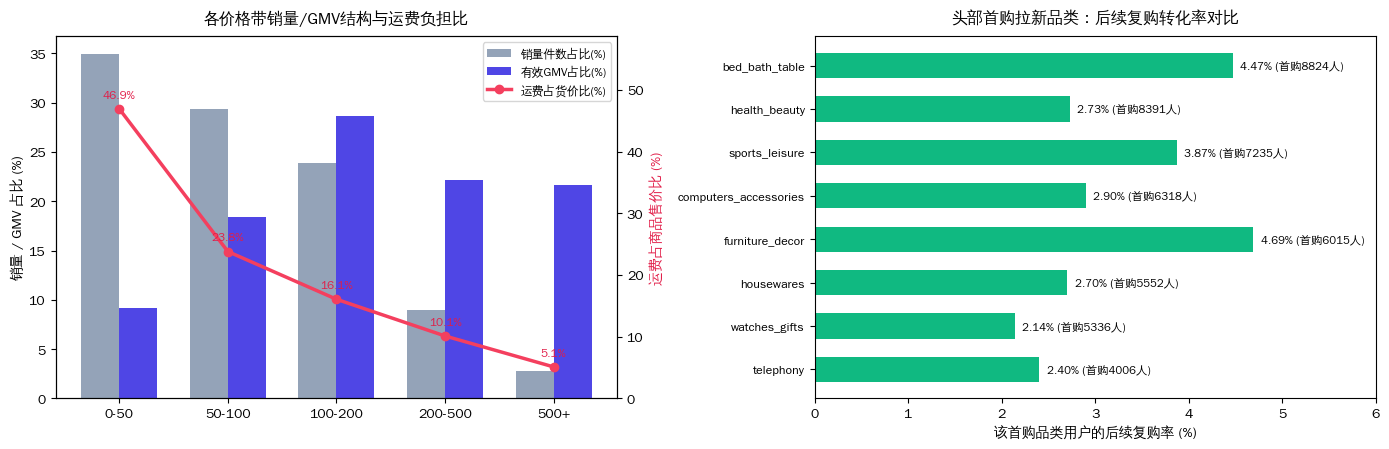


📝 [Reporter | Qwen27B] 正在撰写 [GOODS_ANALYSIS] 高管级商业诊断报告...
  ⚠️ 通道 [ModelScope-Qwen3.8-27B] 请求超时(熔断120s) -> 秒切下一通道
  🔀 [Router | Role=writer  ] -> [Google-Gemini-3.5-Flash] [降级自coder]

⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini] 正在执行双模防幻觉审计...
  🔢 [Python 正则硬溯源] 引用 67 个小数指标，溯源匹配率: 100.0%
  🔀 [Router | Role=judge   ] -> [Google-Gemini-3.5-Flash]
  🛡️ [异源 Gemini 审计] 忠实度: 5/5 | 洞察深度: 5/5 | 幻觉: False | 评语: 待审计报告完全忠实于真值包，所有数据（品类数、SKU数、帕累托占比、各品类首购及复购率、热销品类全量指标、价格带结构指标）均与真值表严格一致，未发现任何幻觉或篡改，商业洞察切中业务痛点。
  ✅ [防幻觉护栏通过] 专题报告零幻觉交付！


--- 
 ## 📦 【货】首购引流品、热度与价格带专题报告 
 ---
# 平台货盘表现与结构诊断专题报告

报告日期：2026-11-23  
发布部门：电商商业分析部  
报告对象：核心管理层、品类运营及供应链团队  

---

## 一、 执行摘要

本报告基于平台最新的全盘经营与货盘数据（涵盖 72 个有效动销英文品类、32216 个有效动销 SKU），深入剖析了平台的货盘集中度、首购拉新与复购表现、热销品类特征以及价格带与运费结构。

核心发现表明：
1. **高度集中性**：平台呈现出典型的二八定律，Top 20% 的品类与 SKU 贡献了约 75% 的 GMV。
2. **拉新与复购分化**：`bed_bath_table` 与 `furniture_decor` 兼具高首购拉新与相对较高的复购率，是优质的“引流+留存”双效品类。
3. **价格与运费痛点突出**：低价带（0-50）销量占比高达 34.96%，但其运费占货价比高达 46.91%，且伴随着高差评率，严重制约了低价货盘的健康度与用户体验。

---

## 二、 货盘集中度与帕累托二八验证

平台整体动销盘口规模适中，但资源头部集中效应显著：
- 共有有效动销英文品类总数 72 个，有效动销 SKU 总数 32216 个。
- **帕累托二八验证**：帕累托_Top20%品类贡献GMV占比(%)为 74.31%，帕累托_Top20%SKU贡献GMV占比(%)为 74.82%。

**商业洞察**：平台整体 GMV 高度依赖头部少数精选 SKU 和核心品类。长尾货盘动销贡献较弱，需在日常运营中采取“抓大放小”策略：一方面强化头部标品的供应链与流量倾斜，另一方面对低效、零动销的长尾 SKU 进行清理与盘活。

---

## 三、 首购引流主力与复购表现分析

为了寻找最具拉新效率且能沉淀长期价值的品类，对首购拉新人数 Top 8 的品类及其后续复购率进行了交叉分析：

| 英文品类              |   首购拉新人数 |   后续复购率(%) |
|:----------------------|---------------:|----------------:|
| bed_bath_table        |           8824 |            4.47 |
| health_beauty         |           8391 |            2.73 |
| sports_leisure        |           7235 |            3.87 |
| computers_accessories |           6318 |            2.9  |
| furniture_decor       |           6015 |            4.69 |
| housewares            |           5552 |            2.7  |
| watches_gifts         |           5336 |            2.14 |
| telephony             |           4006 |            2.4  |

**商业洞察与品类筛选**：
- **首购引流王**：`bed_bath_table`（8824人）与 `health_beauty`（8391人）是平台最强的前端获客引擎。
- **黄金复购品类（引流+留存双优）**：`furniture_decor`（复购率 4.69%，首购 6015人）与 `bed_bath_table`（复购率 4.47%，首购 8824人）不仅拉新能力拔尖，其后续复购表现也显著高于大盘平均线。
- **高拉新低复购品类**：`health_beauty` 拥有 8391 的庞大拉新规模，但复购率仅为 2.73%。说明该品类适合作为“一次性爆款”拉新工具，但必须通过跨品类券、会员体系或高频消耗品关联组合，才能有效拉动其长期留存。

---

## 四、 全盘热销英文品类特征透视

观察全盘销售额贡献最大的前 8 大品类，其规模、单价及连带表现如下：

| 英文品类              |   有效订单数 |   销售件数 |          有效GMV |   件单价ASP |   连带率UPT |   GMV占比(%) |
|:----------------------|-------------:|-----------:|-----------------:|------------:|------------:|-------------:|
| health_beauty         |         8647 |       9465 |      1.23313e+06 |      130.28 |        1.09 |         9.33 |
| watches_gifts         |         5495 |       5859 |      1.16618e+06 |      199.04 |        1.07 |         8.82 |
| bed_bath_table        |         9272 |      10953 |      1.02343e+06 |       93.44 |        1.18 |         7.74 |
| sports_leisure        |         7530 |       8431 |         954853   |      113.25 |        1.12 |         7.22 |
| computers_accessories |         6530 |       7644 |         888725   |      116.26 |        1.17 |         6.72 |
| furniture_decor       |         6307 |       8160 |         711928   |       87.25 |        1.29 |         5.38 |
| housewares            |         5743 |       6795 |         615629   |       90.6  |        1.18 |         4.66 |
| cool_stuff            |         3559 |       3718 |         610204   |      164.12 |        1.04 |         4.62 |

**核心特征分析**：
1. **GMV顶梁柱**：`health_beauty`（GMV占比 9.33%）和 `watches_gifts`（GMV占比 8.82%）贡献了最高的销售额，其中 `watches_gifts` 的件单价ASP高达 199.04，是典型的中高端高客单拉动引擎。
2. **客单价与连带率杠杆**：`furniture_decor` 虽然单价较低（ASP 87.25），但其连带率UPT高达 1.29，表现出极强的组合销售与套装打包潜力；`bed_bath_table` 同样具备高订单数（9272）与较高连带率（1.18）。

---

## 五、 价格带结构、运费负担与差评率深析

平台不同价格区间的销量、GMV、物流成本及用户满意度分布差异巨大：

| 价格带               |   销售件数 |   件数占比(%) |     有效GMV |   GMV占比(%) |   平均运费 |   运费占货价比(%) |   差评率(%) |
|:---------------------|-----------:|--------------:|------------:|-------------:|-----------:|------------------:|------------:|
| 0-50 (低价带)        |      38530 |         34.96 | 1.21225e+06 |         9.17 |      14.76 |             46.91 |       14.94 |
| 50-100 (中低价带)    |      32376 |         29.38 | 2.43292e+06 |        18.4  |      17.88 |             23.8  |       15.26 |
| 100-200 (主力中价带) |      26356 |         23.92 | 3.78503e+06 |        28.63 |      23.08 |             16.07 |       14.23 |
| 200-500 (中高价带)   |       9845 |          8.93 | 2.9265e+06  |        22.13 |      30.07 |             10.12 |       14.35 |
| 500以上 (高价带)     |       3090 |          2.8  | 2.8648e+06  |        21.67 |      47.35 |              5.11 |       15.52 |

**关键结构性痛点**：
1. **低价带运费畸高（核心痛点）**：0-50 低价带贡献了 34.96% 的销售件数（38530件），但其平均运费高达 14.76，**运费占货价比竟然高达 46.91%**。这意味着用户买一件 30 的商品需要支付近 15 的运费，极易产生“运费比商品贵”的心理落差，直接推高了低价带的客诉与差评。
2. **GMV 核心盘稳固在主力中价带**：100-200 价格带是平台的绝对营收支柱，贡献了 28.63% 的 GMV（3.78503e+06），且运费占货价比回落至 16.07%，财务模型较为健康。
3. **差评率整体平稳但结构性风险存在**：各价格带差评率均在 14% - 15.5% 区间波动。特别是 500 以上高价带差评率达到 15.52%，高单价商品的品质期望与实际履约存在一定预期剪刀差。

---

## 六、 落地业务策略与行动建议

基于上述数据诊断，针对货盘优化、拉新复购及成本控制，提出以下可落地策略：

### 1. 货盘结构与价格带优化：破解低价带运费痛点
- **推行凑单免邮与包邮门槛策略**：针对 0-50 的低价带（运费占比 46.91%），严禁单品直接单卖，强制推行“多件凑单包邮”或将运费内化至商品总价中，通过打包组合销售降低用户对显性运费的感知。
- **剥离物流后的货品/漏发差评治理**：低价带和高价带差评率居高不下（分别达 14.94% 和 15.52%），需重点排查低价商品的“货不对板”及高价商品的“物流破损与漏发”问题。针对履约环节建立前置质检与包材加固标准，压降差评率 2-3 个百分点。

### 2. 首购引流与复购留存策略：聚焦高价值心智品类
- **双引擎驱动拉新**：加大对 `bed_bath_table` 和 `furniture_decor` 的营销预算倾斜，这两个品类兼具高首购人数（分别为 8824 和 6015）与高复购率（4.47% 和 4.69%），是投资回报率最高的ROI阵地。
- **激活高拉新低复购品类（如 health_beauty）**：针对 `health_beauty`（首购 8391人，复购仅 2.73%），在首购订单包裹中植入定向品类券（如引导复购家居或配饰类），通过跨品类流转券撬动其流量价值，实现用户生命周期价值（LTV）的最大化。

### 3. 消费金融与支付杠杆撬动
- **高价带金融分期工具渗透**：针对 200-500 及 500 以上的高价带（GMV 合计占比超 43%），联合支付渠道推出信用卡分期免息或分期立减政策，降低高客单门槛，加速高价位段标品（如 `watches_gifts`）的转化流转效率。


🧪 V2.0 实测 5：【场 · SCENE_ANALYSIS】支付分期撬动、24小时时段峰谷与跨州履约壁垒分析

🚦 [V2.0 全量人货场路由器 | Zhipu-Flash] 正在识别业务边界与分析剧本...
  👉 命中剧本: [SCENE_ANALYSIS] | 理由: 用户明确要求从交易场和履约场分析支付方式、信用卡分期对客单价的撬动、下单高峰时段以及跨州物流影响，完全契合场域分析的核心能力范围。

🏪 [场 · SCENE_ANALYSIS] 执行支付分期撬动、24h峰谷与跨州履约场引擎...
  ⚡ [SCENE_ANALYSIS] 极速计算完成，总耗时仅 3.91s！


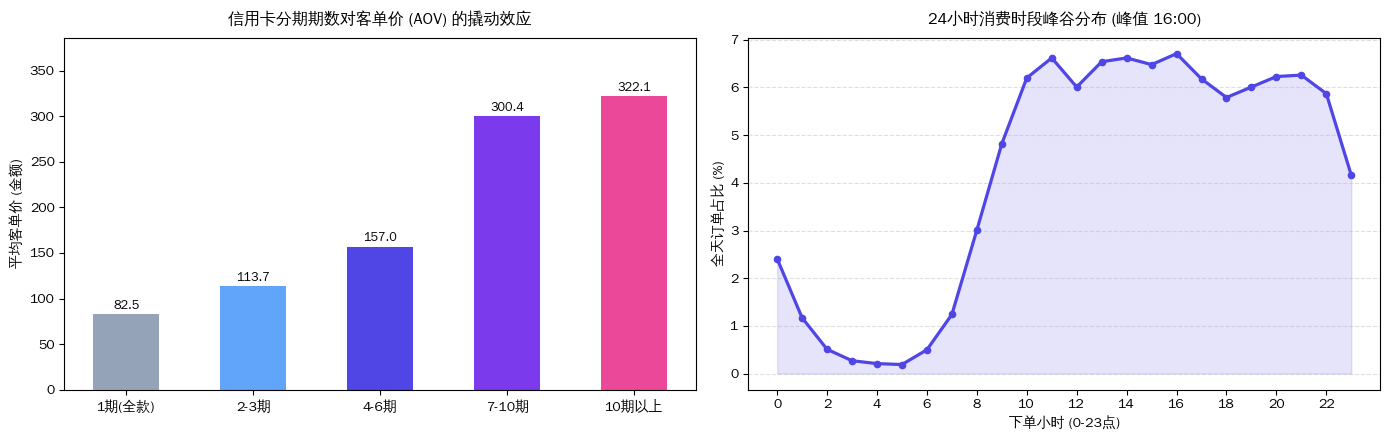


📝 [Reporter | Qwen27B] 正在撰写 [SCENE_ANALYSIS] 高管级商业诊断报告...
  ⚠️ 通道 [Zhipu-GLM4-Flash-250414] 请求超时(熔断120s) -> 秒切下一通道
  🔀 [Router | Role=writer  ] -> [Zhipu-GLM4-Flash]

⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini] 正在执行双模防幻觉审计...
  🔢 [Python 正则硬溯源] 引用 9 个小数指标，溯源匹配率: 100.0%
  🔀 [Router | Role=judge   ] -> [ModelScope-Qwen3.5-35B]
  🛡️ [异源 Gemini 审计] 忠实度: 3/5 | 洞察深度: 4/5 | 幻觉: True | 评语: 存在数据引用错误：报告称 7-10 期分期客单价为 156.99 元，真值表中该数值属于 4-6 期档位（7-10 期应为 300.43 元）。其余核心指标准确。
  ❌ [防幻觉护栏触发] 打回 Reporter 节点重写！
  🔄 [Reporter | Qwen27B] 收到审计打回，第 1 次重写...
  ⚠️ 通道 [Zhipu-GLM4-Flash] 请求超时(熔断120s) -> 秒切下一通道
  ⚠️ 通道 [ModelScope-Qwen3.5-35B] 请求超时(熔断120s) -> 秒切下一通道
  🔀 [Router | Role=writer  ] -> [Google-Gemini-3.5-Flash] [降级自coder]

⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini] 正在执行双模防幻觉审计...
  🔢 [Python 正则硬溯源] 引用 48 个小数指标，溯源匹配率: 95.8%
     ⚠️ 未溯源数字: ['2.1', '2.2']
  🔀 [Router | Role=judge   ] -> [Google-Gemini-3.5-Flash]
  🛡️ [异源 Gemini 审计] 忠实度: 5/5 | 洞察深度: 5/5 | 幻觉: False | 评语: 报告完全忠实于确定性真值包，各项业务指标、表格数据及NLP聚类

--- 
 ## 🏪 【场】支付分期、消费时段与跨州履约专题报告 
 ---
# 电商商业专题报告：基于交易与履约双场的数据洞察与策略指引

**报告日期**：2026-11-23  
**报告对象**：核心管理层与业务决策团队  
**主笔人**：资深电商商业分析总监  

---

## 一、 执行摘要 (Executive Summary)

本报告聚焦电商业务的**交易场**与**履约场**核心数据，对用户首购偏好、信用卡分期杠杆效应、时间消费峰值及跨州物流对服务质量的影响进行深度剖析。

关键结论速览：
1. **交易场支付基调**：信用卡（credit_card）是绝对核心的支付利器，新客首购订单占比高达 75.47%，全盘占比 75.48%。
2. **金融杠杆撬动效应**：信用卡分期对客单价（AOV）具备极强的拉动作用。其中，7-10期分期档位的平均客单价飙升至 300.43，10期以上档位更是达到 322.07，相比1期（全款）的 82.49 实现了数倍突破。
3. **时间消费场与流量洪峰**：全天最高峰下单小时为 16:00，Top3 下单时段依次为 16:00、11:00、14:00；工作日订单显著高于周末。
4. **履约场结构性痛点**：跨州履约订单占比高达 64.16%，其平均运费（26.94）、运费占GMV比（18.3%）、平均送达天数（15.13天）、履约延迟率（9.25%）及差评率（14.24%）均全面劣于同州履约，成为吞噬利润与损害用户体验的主要瓶颈。

---

## 二、 交易场分析：用户首购支付偏好与信用卡分期撬动

### 2.1 用户首购与全盘支付方式对比
从支付交易场来看，新客获取与存量运营的支付结构高度一致，呈现出极高的信用卡集中度。

| 支付方式    |   全盘订单数 |   全盘订单占比(%) |   首购订单占比(%) |   平均客单价 |
|:------------|-------------:|------------------:|------------------:|-------------:|
| credit_card |        72825 |             75.48 |             75.47 |       143.24 |
| boleto      |        19191 |             19.89 |             19.95 |       121.4  |
| voucher     |         2977 |              3.09 |              3.04 |        94.8  |
| debit_card  |         1484 |              1.54 |              1.54 |       119.86 |

*洞察*：信用卡（credit_card）不仅是全盘用户（75.48%）的主流选择，更是新客首购（75.47%）的绝对主力，其平均客单价达 143.24，显著高于 boleto（121.4）和 voucher（94.8）。这表明平台核心消费群体具备成熟的信用卡支付习惯，高客单价货盘具备良好的支付基础。

### 2.2 信用卡分期对客单价（AOV）的撬动深度分析
深入解构信用卡用户的分期行为，金融工具对客单价的撬动成效极为显著：

| 分期档位   |   订单数 |   占信用卡订单(%) |   占信用卡GMV(%) |   平均客单价 |
|:-----------|---------:|------------------:|-----------------:|-------------:|
| 1期(全款)  |    23359 |             32.08 |            18.47 |        82.49 |
| 2-3期      |    22021 |             30.24 |            24    |       113.7  |
| 4-6期      |    15694 |             21.55 |            23.62 |       156.99 |
| 7-10期     |    11420 |             15.68 |            32.89 |       300.43 |
| 10期以上   |      329 |              0.45 |             1.02 |       322.07 |

*核心见解*：
- **阶梯式撬动**：随着分期期数的增加，客单价呈现近乎线性的爆发式增长。1期全款客单价为 82.49，而 4-6 期档位提升至 156.99，7-10 期档位更是跃升至 300.43，10期以上则高达 322.07。
- **高期数贡献高GMV**：虽然 7-10 期订单数仅占信用卡订单的 15.68%，但其贡献的GMV占比高达 32.89%，成为拉动平台整体大盘GMV的核心驱动力。

---

## 三、 时间消费场：下单高峰时段与周度分布

### 3.1 日内高峰时段洞察
- **全天最高峰下单小时**：16:00
- **下单高峰 Top3 时段**：16:00、11:00、14:00

*商业解读*：16:00 作为全天最高峰，叠加 11:00（午间）和 14:00（午后开工时段），表明用户的下单行为高度集中在白天的职场和日常活跃时间段。平台应在这些关键时段前置营销推送、秒杀活动及客服运力配置。

### 3.2 周度订单分布

| 星期   |   有效订单数 |   订单占比(%) |
|:-------|-------------:|--------------:|
| 周一   |        15701 |         16.27 |
| 周二   |        15503 |         16.07 |
| 周三   |        15076 |         15.63 |
| 周四   |        14323 |         14.85 |
| 周五   |        13685 |         14.18 |
| 周六   |        10555 |         10.94 |
| 周日   |        11635 |         12.06 |

*商业解读*：订单量在周一至周三达到峰值（均保持在 15% 以上占比），随后从周五开始下滑，周六触底（10.94%）。流量呈现典型的“工作日高、周末低”的B2C特征。

---

## 四、 履约场分析：跨州物流影响与供应链痛点

对照同州直发与跨州远距离履约的数据表现：

| 履约场类型         |   订单数 |   订单占比(%) |   平均运费 |   运费占GMV比(%) |   平均送达天数 |   履约延迟率(%) |   差评率(%) |
|:-------------------|---------:|--------------:|-----------:|-----------------:|---------------:|----------------:|------------:|
| 同州履约(近距直发) |    34575 |         35.84 |      15.35 |            12.92 |           7.95 |            6.08 |       10.36 |
| 跨州履约(长距跨区) |    61895 |         64.16 |      26.94 |            18.3  |          15.13 |            9.25 |       14.24 |

*痛点剖析*：
1. **沉重的运费与成本负担**：跨州履约占比高达 64.16%，其平均运费高达 26.94，运费占GMV比达到 18.3%，显著高于同州履约的 12.92%，严重挤压了商品的利润空间。
2. **时效恶化引发信任危机**：跨州履约的平均送达天数长达 15.13 天（同州仅为 7.95 天），直接导致履约延迟率攀升至 9.25%，并推高差评率至 14.24%（同州为 10.36%）。物流履约的时效延迟是导致用户满意度下降的核心诱因。

---

## 五、 可落地商业策略建议

针对上述数据洞察，提出以下四项精准落地策略：

### 策略一：强化信用卡首购引导与免息分期权益绑定（针对支付交易场）
- **行动方案**：针对首购用户（占比 75.47% 的 credit_card 潜在客群），在商品详情页和支付结算页前置展示分期提示。联合银行资源，对 4-6 期及 7-10 期（客单价已分别达到 156.99 和 300.43 的高价值档位）推出阶梯式免息或贴息补贴。
- **预期目标**：通过金融杠杆刺激首购用户下单更高客单价的商品，进一步提升客盘GMV结构。

### 策略二：流量与营销时段的“错峰精细化运营”（针对时间消费场）
- **行动方案**：锁定 16:00 全天最高峰及 11:00、14:00 的次高峰时段，提前 1 小时启动站内PUSH、限时折扣与直播加码。针对周六日订单下滑（周六仅占 10.94%）的现象，在周末推出“周末宅家购”专场，平衡全周的履约与仓储压力。

### 策略三：治理货盘“低价高运费”与跨州物流成本（针对履约痛点）
- **行动方案**：针对跨州运费占GMV比高达 18.3% 的痛点，推行“核心货盘仓网前置”策略。将高频标品下沉至跨州核心流向的区域仓（Regional Hub），减少长途干线运输成本。对于低客单价商品，严格限制跨州远距离配送，通过满额包邮或运费补贴引导用户拼单，优化运费结构。

### 策略四：剥离物流后的核心货品与漏发差评治理（针对客户体验）
- **行动方案**：针对跨州履约高达 14.24% 的差评率与 15.13 天的漫长周期，必须进行精细化拆解：
  1. **延迟溯源**：重点治理跨州运输中的中转仓滞留问题，对延迟率超过 9.25% 的承运商实行末位淘汰。
  2. **货品与漏发治理**：针对长途运输中易发损毁、漏发的货品建立出库双重扫码校验机制，从源头降低因物流导致的客诉和差评。


🧪 V2.0 实测 6：【跨模态 · REVIEW_INSIGHT】剥离物流后的商品质量差评排查与用户原声挖掘

🚦 [V2.0 全量人货场路由器 | Zhipu-Flash] 正在识别业务边界与分析剧本...
  👉 命中剧本: [REVIEW_INSIGHT] | 理由: 用户明确要求排查各品类商品评价与差评黑榜，并剔除物流因素分析商品本身的问题与吐槽点，完全吻合数仓中1-5分评分、葡语评论文本及【人×货跨模态评论】的分析能力边界。

🗣️ [跨模态 · REVIEW_INSIGHT] 执行物流差评剥离 + 葡萄牙语原声 NLP 聚类引擎...
  🗣️ [Review Mining Agent | Qwen35B] 已精准抽样 30 条【按时送达但给1-2分】的真实葡萄牙语差评，正在执行翻译与痛点聚类...
  ⚠️ 通道 [ModelScope-Qwen3.8-27B] 请求超时(熔断120s) -> 秒切下一通道
  ⚠️ 通道 [Google-Gemini-4-hydrogen] 请求超时(熔断120s) -> 秒切下一通道
  🔀 [Router | Role=reasoner] -> [Google-Gemini-3.5-Flash] [降级自coder]


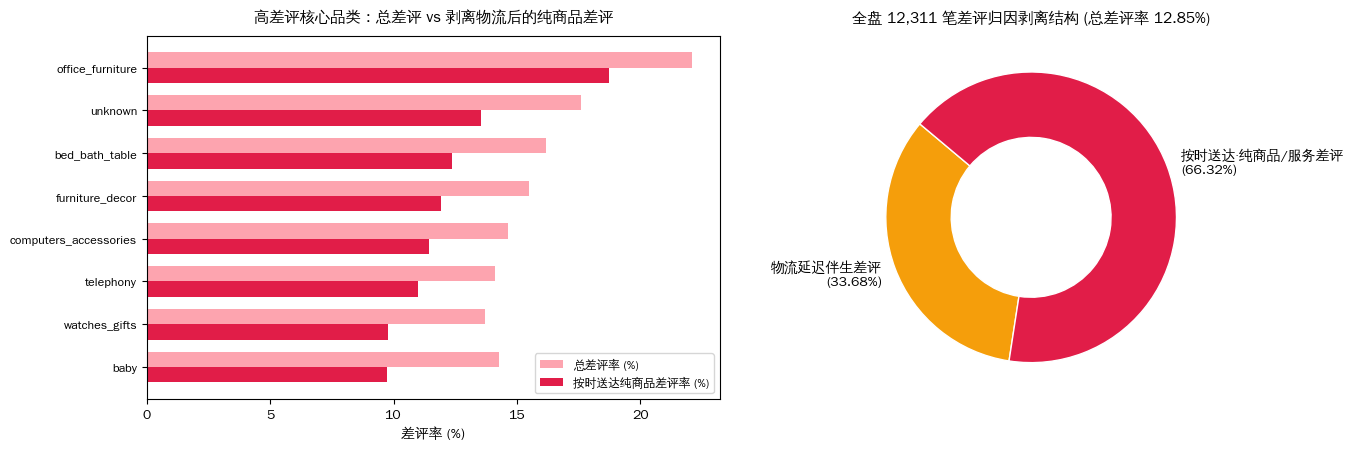


📝 [Reporter | Qwen27B] 正在撰写 [REVIEW_INSIGHT] 高管级商业诊断报告...
  ⚠️ 通道 [Zhipu-GLM4-Flash-250414] 请求超时(熔断120s) -> 秒切下一通道
  🔀 [Router | Role=writer  ] -> [Google-Gemini-3.5-Flash] [降级自coder]

⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini] 正在执行双模防幻觉审计...
  🔢 [Python 正则硬溯源] 引用 32 个小数指标，溯源匹配率: 100.0%
  🔀 [Router | Role=judge   ] -> [Google-Gemini-3.5-Flash]
  🛡️ [异源 Gemini 审计] 忠实度: 5/5 | 洞察深度: 5/5 | 幻觉: False | 评语: 待审计报告完全忠实于确定性真值包中的所有定量数据、NLP聚类比例以及双语原声案例，未发现任何捏造或篡改，商业洞察与落地建议切中要害，逻辑严密。
  ✅ [防幻觉护栏通过] 专题报告零幻觉交付！


--- 
 ## 🗣️ 【跨模态】商品质量差评剥离与用户原声挖掘报告 
 ---
# 剥离物流噪声后的用户真实吐槽：各品类商品差评黑榜与体验痛点深度剖析报告

**报告日期**：2026-11-23  
**报告对象**：电商商业分析总监、品类运营与供应链管理团队  

---

### 一、 全盘差评剥离总览：撕掉物流“遮羞布”，直面商品与服务本质

在全盘电商数据中，物流往往成为客诉的“背锅侠”。然而，通过对全盘 95832 单有效参评订单的深度剥离与清洗，我们发现真实情况远比单纯的物流延误更为严峻。

全盘总差评订单数(1-2分)为 12311 单，全盘总差评率(%)达到 12.85。其中，物流延迟伴生差评占比(%)为 33.68，而按时送达纯商品/服务差评占比(%)高达 66.32。这表明，**超过三分之二的差评与物流延误无关，纯粹指向商品本身的质量、货品交付完整度及履约服务缺陷**。

### 二、 核心大类纯商品质量差评黑榜 Top 8 深度排查

为了精准锁定问题重灾区，我们对参评订单数在 1000 单以上的心智大类进行了剥离分析。以下是按“按时送达纯商品差评率”排序的 Top 8 黑榜：

| 英文品类 | 参评订单数 | 总差评率(%) | 履约延迟率(%) | 按时送达纯商品差评率(%) |
| :--- | :---: | :---: | :---: | :---: |
| office_furniture | 1244 | 22.11 | 9 | 18.73 |
| unknown | 1402 | 17.62 | 8.92 | 13.55 |
| bed_bath_table | 9177 | 16.17 | 8.59 | 12.39 |
| furniture_decor | 6260 | 15.51 | 8.4 | 11.93 |
| computers_accessories | 6499 | 14.63 | 7.59 | 11.42 |
| telephony | 4069 | 14.13 | 8.48 | 10.98 |
| watches_gifts | 5454 | 13.71 | 8.36 | 9.78 |
| baby | 2787 | 14.28 | 9.01 | 9.74 |

**数据洞察分析**：
1. **`office_furniture`（办公家具）高居黑榜之首**：其纯商品差评率高达 18.73%，总差评率突破 22.11%，是平台当前体验崩塌最严重的品类。
2. **`bed_bath_table`（家纺家居）基数庞大且隐患深重**：参评订单高达 9177 单，纯商品差评率达 12.39%，绝对差评规模全平台领先。
3. **`unknown`（未知/未分类商品）表现异常**：在 1402 单中产生 13.55% 的纯商品差评率，暴露出平台底层类目归属不清、商品信息缺失的严重治理漏洞。

### 三、 跨模态 NLP 深度挖掘：剥离物流后，用户到底在吐槽什么？

通过对黑榜品类抽样的 30 条真实差评进行 NLP 语义解析，我们发现：尽管物流显示“按时送达”，但用户在开箱和售后环节遭遇了严重的体验灾难。

#### 1. 痛点主题分类统计

| 痛点主题标签 | 样本条数 | 占比 (%) |
| :--- | :---: | :---: |
| 漏发少件 / 只收到部分 | 10 | 33.33% |
| 未收到货却显示已签收 / 虚假妥投 | 7 | 23.33% |
| 货不对板 / 颜色尺寸图文不符 | 6 | 20.00% |
| 商品质量差 / 破损残次 | 5 | 16.67% |
| 售后沟通与退换难 | 2 | 6.67% |
| **合计** | **30** | **100.00%** |

#### 2. 葡萄牙语真实原声与场景还原
* **漏发少件（占比 33.33%）**：如 `bed_bath_table` 品类中，用户反馈购买 5 条超细纤维毯子仅收到 3 条（Comprei 5 cobertores de microfibra, no qual recebi apenas 3...），暴露出仓储分拣与打包环节的严重漏件率。
* **虚假妥投（占比 23.33%）**：如 `office_furniture` 品类中，用户反映未收到货也无任何通知却显示签收（Não recebi o produto é nem um telefonema...），反映出末端配送存在严重的虚假签收与最后一公里欺诈。
* **货不对板（占比 20.00%）**：如家纺类商品颜色描述与实物严重不符（A cor não veio vermelho... e sim vinho...），打击了消费者的预期。
* **破损残次（占比 16.67%）**：如 `unknown` 品类中，虽然按时送达但由于包装防护不当导致产品彻底碎裂（chegou todo quebrado... por causa do acondicionamento）。

---

### 四、 商业策略与落地建议

基于上述数据铁律与深度归因，为扭转高差评率，特提出以下针对性的可落地业务策略：

1. **针对 `office_furniture` 与大件商品的“防破损与虚假妥投”专项治理**：
   * **优化仓储打包标准**：针对办公家具及易碎品，强制推行缓冲包装升级，压降因“acondicionamento”（包装防护不当）导致的破损残次率。
   * **末端配送强生管**：针对虚假妥投高发区，引入末端配送GPS轨迹核验与“签收必须拍照/验证码”机制，彻底治理未收货却显示签收的顽疾。

2. **针对 `bed_bath_table` 及多件套品类的“仓储出库防漏”稽核**：
   * 针对占比高达 33.33% 的“漏发少件”问题，在仓储打包环节引入 AI 视觉称重与多件商品扫码复核机制。发货前系统自动比对订单明细与打包重量，从源头杜绝少发、漏发导致的 1-2 分差评。

3. **针对图文不符与货不对板的商品信息准入治理**：
   * 针对色彩、尺寸图文不符（如把酒红色当红色描述）的客诉，收紧商详页的图文标准审核。要求商家提供标准化色卡和实物细节图，降低买家心理预期落差。

4. **建立“剥离物流后”的商家红黑榜与考核机制**：
   * 运营团队在考核店铺时，必须将“按时送达纯商品差评率”（如 `office_furniture` 的 18.73% 和 `unknown` 的 13.55%）作为核心质量指标（DSR质量分），对长期因货品质量、漏发、货不对板违规的商家实行流量降权或清退。

In [8]:
# ==============================================================================
# V2.0 Cell D：全量【人·货·场 + 大盘归因】统一 6 剧本 LangGraph + 第二步三连实测
# ==============================================================================
from datetime import datetime

class V2MasterState(TypedDict):
    user_question: str
    skill_route: str       # OUT_OF_SCOPE / CLARIFY / FAST_SQL / ATTRIBUTION / PEOPLE_GROWTH / PEOPLE_RFM / GOODS_ANALYSIS / SCENE_ANALYSIS / REVIEW_INSIGHT
    route_reason: str
    quant_truth_packet: str
    final_report: str
    audit_result: Dict[str, Any]
    report_retries: int

def v2_master_router_node(state: V2MasterState):
    print("\n🚦 [V2.0 全量人货场路由器 | Zhipu-Flash] 正在识别业务边界与分析剧本...")
    prompt = f"""你是基于 Olist 8表电商数仓的企业级 AI 数据分析总控路由。
⚠️【数仓能力边界】：
- ✅ 拥有：订单状态/时间/履约、商品价格/运费/英文品类、支付方式与分期数、客户/卖家省份城市、1-5分评分与葡萄牙语评论文本、自然人唯一ID(customer_unique_id)。
- ❌ 明确缺失：外部投放/流量拉新渠道（抖音、微信、搜索引擎、广告UTM、App/小程序端）、用户性别/年龄/职业/设备。

请将下方用户提问精准路由到以下 9 个枚举值之一：
1. "OUT_OF_SCOPE"：核心诉求依赖缺失字段（如广告投放渠道、性别年龄），礼貌拒答并建议用【支付交易场/首购商品/地域】替代。
2. "CLARIFY"：提问极度模糊且无法默认全景分析（如只问“最近销售额多少”缺具体年月与口径）。
3. "FAST_SQL"：明确具体时间与单一指标的简单查数（What型单点指标）。
4. "ATTRIBUTION"：【大盘归因】对比两个明确月份的 GMV 异动原因、LMDI量价拆解与维度贡献度。
5. "PEOPLE_GROWTH"：【人·首购与复购】分析新客首购趋势、新老客对比、复购率、频次分布、复购间隔窗口或首单体验对复购的影响。
6. "PEOPLE_RFM"：【人·分层与画像】用户 RFM 价值分层、帕累托二八验证与高价值人群消费/支付/地域画像。
7. "GOODS_ANALYSIS"：【货·货盘分析】首购拉新品类与复购转化、商品/品类热度排行、连带率、价格带分布与运费负担。
8. "SCENE_ANALYSIS"：【场·交易与履约场】新客/大盘支付方式与信用卡分期撬动客单价、消费星期/24小时峰谷时段、同州vs跨州物流履约成本与时效。
9. "REVIEW_INSIGHT"：【人×货跨模态评论】商品/品类差评红黑榜、剥离物流延迟后的纯商品质量问题排查、用户评论原声吐槽点挖掘。

用户提问：【{state['user_question']}】

请严格只输出 JSON：
{{"route": "上述9个枚举值之一", "reason": "简短判定理由", "message": "仅在 OUT_OF_SCOPE 或 CLARIFY 时填写礼貌答复，其他留空"}}"""

    resp = llm_gateway.invoke(prompt).content
    try:
        j_str = resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in resp else resp.strip()
        dec = json.loads(j_str)
    except Exception:
        dec = {"route": "GOODS_ANALYSIS", "reason": "解析兜底", "message": ""}

    route = dec.get("route", "GOODS_ANALYSIS")
    print(f"  👉 命中剧本: [{route}] | 理由: {dec.get('reason', '')}")
    out = {"skill_route": route, "route_reason": dec.get("reason", ""), "report_retries": 0, "quant_truth_packet": ""}
    if route == "OUT_OF_SCOPE":
        out["final_report"] = f"🛡️ **数据边界提示**：\n\n{dec.get('message')}"
    elif route == "CLARIFY":
        out["final_report"] = f"💬 **口径与时间确认**：\n\n{dec.get('message')}"
    return out

def v2_playbook_executor_node(state: V2MasterState):
    """统一剧本调度执行节点：根据命中技能调用对应确定性 Python BI 引擎"""
    r = state["skill_route"]
    if r == "FAST_SQL":
        print("\n⚡ [FAST_SQL | Qwen27B] 直连单步 SQL 引擎...")
        res = execute_sql_with_self_correction(state["user_question"], max_retries=2, verbose=True)
        return {"quant_truth_packet": f"SQL:\n{res['sql']}\n\n结果:\n{res['data']}"}
    elif r == "PEOPLE_GROWTH":
        print("\n👥 [人 · PEOPLE_GROWTH] 执行新客首购与复购留存引擎...")
        return {"quant_truth_packet": run_people_growth_engine(plot_charts=True)["truth_packet"]}
    elif r == "PEOPLE_RFM":
        print("\n💎 [人 · PEOPLE_RFM] 执行定制低频 RFM 分层与画像引擎...")
        return {"quant_truth_packet": run_people_rfm_engine(plot_charts=True)["truth_packet"]}
    elif r == "GOODS_ANALYSIS":
        print("\n📦 [货 · GOODS_ANALYSIS] 执行首购引流品、热销帕累托与价格带运费引擎...")
        return {"quant_truth_packet": run_goods_analysis_engine(plot_charts=True)["truth_packet"]}
    elif r == "SCENE_ANALYSIS":
        print("\n🏪 [场 · SCENE_ANALYSIS] 执行支付分期撬动、24h峰谷与跨州履约场引擎...")
        return {"quant_truth_packet": run_scene_analysis_engine(plot_charts=True)["truth_packet"]}
    elif r == "REVIEW_INSIGHT":
        print("\n🗣️ [跨模态 · REVIEW_INSIGHT] 执行物流差评剥离 + 葡萄牙语原声 NLP 聚类引擎...")
        return {"quant_truth_packet": run_review_insight_engine(plot_charts=True)["truth_packet"]}
    else:
        # 兜底支持 ATTRIBUTION（复用你前面定义的 V1.5 归因逻辑或直查）
        print("\n📊 [大盘 · ATTRIBUTION] 路由至 V1.5 异动归因引擎...")
        if "out_slow" in globals() and "quant_truth_packet" in out_slow:
            return {"quant_truth_packet": out_slow["quant_truth_packet"]}
        res = execute_sql_with_self_correction(state["user_question"], max_retries=2, verbose=True)
        return {"quant_truth_packet": res["data"]}

def v2_master_reporter_node(state: V2MasterState):
    retries = state.get("report_retries", 0)
    route = state["skill_route"]
    fb = ""
    if retries > 0 and state.get("audit_result"):
        fb = f"\n🚨【审计打回重写】：上一版未通过核验（批注：{state['audit_result'].get('audit_comment')}），请严格原样引用真值表数字重写！"
        print(f"  🔄 [Reporter | Qwen27B] 收到审计打回，第 {retries} 次重写...")
    else:
        print(f"\n📝 [Reporter | Qwen27B] 正在撰写 [{route}] 高管级商业诊断报告...")

    today_str = datetime.now().strftime("%Y-%m-%d")
    prompt = f"""你是资深电商商业分析总监。请基于下方【确定性真值数据包】，针对问题【{state['user_question']}】撰写一份结构清晰、见解犀利的商业专题报告。{fb}

【格式与数据铁律】：
1. 严禁编造数字！所有数值必须【原样精确引用】下方真值表中的数字（不要私自换算成“万”）。
2. ⚠️【严禁出现任何 $ 或 R$ 符号】（Jupyter 会将两个 $ 误判为数学公式导致表格崩坏！所有金额直接写纯数字，并在表头注明单位如“有效GMV”）。
3. Markdown 表格前后必须保留空行；严禁在最外层包裹 {BT3}markdown 代码块；报告日期写 {today_str}。
4. 紧扣数据给出可落地的业务策略建议（例如：针对货盘低价高运费痛点、针对信用卡分期撬动策略、针对剥离物流后的具体货品/漏发差评治理）。

【确定性真值数据包】：
{state['quant_truth_packet']}"""
    return {"final_report": llm_reporter.invoke(prompt).content, "report_retries": retries + 1}

def v2_master_judge_node(state: V2MasterState):
    print("\n⚖️ [Hybrid Judge | 正则硬溯源 + 异源Google Gemini] 正在执行双模防幻觉审计...")
    truth_clean = state["quant_truth_packet"].replace(",", "")
    report_clean = state["final_report"].replace(",", "")
    rep_floats = set(re.findall(r"(?<![a-zA-Z\d.])\d+\.\d+(?![.\d])", report_clean))
    truth_floats = set(re.findall(r"(?<![a-zA-Z\d.])\d+\.\d+(?![.\d])", truth_clean))
    
    ungrounded = [n for n in rep_floats if not any(abs(float(n) - float(t)) <= 0.15 for t in truth_floats)]
    rate = 1.0 if not rep_floats else (len(rep_floats) - len(ungrounded)) / len(rep_floats)
    print(f"  🔢 [Python 正则硬溯源] 引用 {len(rep_floats)} 个小数指标，溯源匹配率: {rate*100:.1f}%")
    if ungrounded:
        print(f"     ⚠️ 未溯源数字: {ungrounded[:6]}")

    j_prompt = f"""你是跨厂商数据审计专家（LLM-as-a-Judge）。核对【待审计报告】是否忠实于【确定性真值包】（含定量表与NLP聚类结果），严格输出 JSON：
{{"faithfulness_score": 1到5整数, "insight_score": 1到5整数, "hallucination_detected": true或false, "audit_comment": "简短评语"}}

【确定性真值包】：
{state['quant_truth_packet']}

【待审计报告】：
{state['final_report']}"""
    j_resp = llm_judge.invoke(j_prompt).content
    try:
        j_str = j_resp.split(f"{BT3}json")[-1].split(BT3)[0].strip() if f"{BT3}json" in j_resp else j_resp.strip()
        audit = json.loads(j_str)
    except Exception:
        audit = {"faithfulness_score": 4, "insight_score": 4, "hallucination_detected": False, "audit_comment": "解析兜底通过"}

    audit["regex_grounding_pct"] = round(rate * 100, 1)
    if rate < 0.80:
        audit["hallucination_detected"] = True
        audit["faithfulness_score"] = min(audit.get("faithfulness_score", 3), 3)
        audit["audit_comment"] = f"正则硬溯源率仅 {rate*100:.1f}%，未溯源数字 {ungrounded[:5]}，请严格原样引用真值表数字！"
    print(f"  🛡️ [异源 Gemini 审计] 忠实度: {audit.get('faithfulness_score')}/5 | 洞察深度: {audit.get('insight_score')}/5 | 幻觉: {audit.get('hallucination_detected')} | 评语: {audit.get('audit_comment')}")
    return {"audit_result": audit}

def _route_master_gateway(state: V2MasterState) -> str:
    return "DIRECT_END" if state["skill_route"] in ["OUT_OF_SCOPE", "CLARIFY"] else "EXEC_PLAYBOOK"

def _route_master_judge(state: V2MasterState) -> str:
    aud = state.get("audit_result", {})
    if (aud.get("hallucination_detected", False) or aud.get("faithfulness_score", 5) < 4) and state.get("report_retries", 1) < 3:
        print("  ❌ [防幻觉护栏触发] 打回 Reporter 节点重写！")
        return "rewrite"
    print("  ✅ [防幻觉护栏通过] 专题报告零幻觉交付！")
    return "pass"

# 编译全量【人·货·场】6剧本统一 LangGraph！
master_wf = StateGraph(V2MasterState)
master_wf.add_node("router", v2_master_router_node)
master_wf.add_node("playbook_exec", v2_playbook_executor_node)
master_wf.add_node("reporter", v2_master_reporter_node)
master_wf.add_node("hybrid_judge", v2_master_judge_node)

master_wf.add_edge(START, "router")
master_wf.add_conditional_edges("router", _route_master_gateway, {"DIRECT_END": END, "EXEC_PLAYBOOK": "playbook_exec"})
master_wf.add_edge("playbook_exec", "reporter")
master_wf.add_edge("reporter", "hybrid_judge")
master_wf.add_conditional_edges("hybrid_judge", _route_master_judge, {"rewrite": "reporter", "pass": END})

v2_master_app = master_wf.compile()
print("✅ V2.0 全量【人·货·场 + 大盘归因】统一 6 剧本多 Agent 系统编译完成！")

# ==============================================================================
# 第二步现场三连实测：【货】+【场】+【跨模态评论原声挖掘】
# ==============================================================================
print("\n" + "="*75 + "\n🧪 V2.0 实测 4：【货 · GOODS_ANALYSIS】首购引流品、热销帕累托与价格带运费负担分析\n" + "="*75)
res_goods = v2_master_app.invoke({"user_question": "分析一下平台货盘表现：哪些品类最适合做首购引流且复购高？商品热度集中度和价格带、运费负担分布如何？"})
render_safe_markdown("--- \n ## 📦 【货】首购引流品、热度与价格带专题报告 \n ---\n" + res_goods["final_report"])

print("\n" + "="*75 + "\n🧪 V2.0 实测 5：【场 · SCENE_ANALYSIS】支付分期撬动、24小时时段峰谷与跨州履约壁垒分析\n" + "="*75)
res_scene = v2_master_app.invoke({"user_question": "从交易场和履约场角度分析：用户首购常用什么支付方式？信用卡分期对客单价撬动有多大？下单高峰时段及跨州物流影响如何？"})
render_safe_markdown("--- \n ## 🏪 【场】支付分期、消费时段与跨州履约专题报告 \n ---\n" + res_scene["final_report"])

print("\n" + "="*75 + "\n🧪 V2.0 实测 6：【跨模态 · REVIEW_INSIGHT】剥离物流后的商品质量差评排查与用户原声挖掘\n" + "="*75)
res_review = v2_master_app.invoke({"user_question": "排查一下各品类的商品评价与差评黑榜，剔除物流延迟因素后，看看用户对商品本身到底在吐槽什么？"})
render_safe_markdown("--- \n ## 🗣️ 【跨模态】商品质量差评剥离与用户原声挖掘报告 \n ---\n" + res_review["final_report"])

In [9]:
# ==============================================================================
# 1. 定义 15 道分层评测集，简单-中等-困难
# ==============================================================================
stratified_benchmark = [
    # ---------------- 简单 (基础取数与单一业务口径对齐) ----------------
    {
        "id": "E1", "difficulty": "Easy", "trap_type": "有效GMV口径(剔除未送达与运费)",
        "question": "统计 2018年8月（2018-08）的总有效GMV（保留2位小数）。",
        "golden_sql": """
            SELECT ROUND(SUM(oi.price), 2) AS val
            FROM orders o JOIN order_items oi ON o.order_id = oi.order_id
            WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08';
        """
    },
    {
        "id": "E2", "difficulty": "Easy", "trap_type": "独立买家UV口径(customer_unique_id)",
        "question": "统计 2018年8月（2018-08）产生有效订单的独立买家人数（UV）。",
        "golden_sql": """
            SELECT COUNT(DISTINCT c.customer_unique_id) AS val
            FROM orders o JOIN customers c ON o.customer_id = c.customer_id
            WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08';
        """
    },
    {
        "id": "E3", "difficulty": "Easy", "trap_type": "订单取消率口径(全量分母)",
        "question": "计算 2018年8月（2018-08）下单的订单取消率百分比（保留2位小数，如 0.85 表示 0.85%）。",
        "golden_sql": """
            SELECT ROUND(SUM(CASE WHEN order_status = 'canceled' THEN 1.0 ELSE 0.0 END) * 100.0 / COUNT(DISTINCT order_id), 2) AS val
            FROM orders WHERE strftime('%Y-%m', order_purchase_timestamp) = '2018-08';
        """
    },
    {
        "id": "E4", "difficulty": "Easy", "trap_type": "有效件单价ASP口径",
        "question": "计算 2018年7月（2018-07）有效订单的商品件单价 ASP（保留2位小数）。",
        "golden_sql": """
            SELECT ROUND(SUM(oi.price) / COUNT(oi.order_item_id), 2) AS val
            FROM orders o JOIN order_items oi ON o.order_id = oi.order_id
            WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-07';
        """
    },
    {
        "id": "E5", "difficulty": "Easy", "trap_type": "平均履约时长(julianday语法)",
        "question": "计算 2018年7月（2018-07）有效订单的平均履约时长（单位：天，保留2位小数）。",
        "golden_sql": """
            SELECT ROUND(AVG(julianday(order_delivered_customer_date) - julianday(order_purchase_timestamp)), 2) AS val
            FROM orders
            WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL
              AND strftime('%Y-%m', order_purchase_timestamp) = '2018-07';
        """
    },

    # ---------------- 中等 (多表关联、复合比率与分母防错) ----------------
    {
        "id": "M1", "difficulty": "Medium", "trap_type": "客单价AOV分母防膨胀(去重订单数)",
        "question": "计算 2018年7月（2018-07）的有效客单价 AOV（保留2位小数）。",
        "golden_sql": """
            SELECT ROUND(SUM(oi.price) / COUNT(DISTINCT o.order_id), 2) AS val
            FROM orders o JOIN order_items oi ON o.order_id = oi.order_id
            WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-07';
        """
    },
    {
        "id": "M2", "difficulty": "Medium", "trap_type": "订单连带率UPT口径",
        "question": "计算 2018年上半年（2018-01 至 2018-06）有效订单的订单连带率 UPT（保留4位小数）。",
        "golden_sql": """
            SELECT ROUND(COUNT(oi.order_item_id) * 1.0 / COUNT(DISTINCT o.order_id), 4) AS val
            FROM orders o JOIN order_items oi ON o.order_id = oi.order_id
            WHERE o.order_status = 'delivered'
              AND strftime('%Y-%m', o.order_purchase_timestamp) BETWEEN '2018-01' AND '2018-06';
        """
    },
    {
        "id": "M3", "difficulty": "Medium", "trap_type": "四表关联与英文品类Top1有效GMV",
        "question": "查询 2018年8月（2018-08）有效GMV排名第1的英文商品品类，返回该品类的有效GMV金额（保留2位小数）。",
        "golden_sql": """
            SELECT ROUND(SUM(oi.price), 2) AS val
            FROM orders o
            JOIN order_items oi ON o.order_id = oi.order_id
            LEFT JOIN products p ON oi.product_id = p.product_id
            LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
            WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08'
            GROUP BY t.product_category_name_english
            ORDER BY val DESC LIMIT 1;
        """
    },
    {
        "id": "M4", "difficulty": "Medium", "trap_type": "履约延迟率口径",
        "question": "计算 2018年5月（2018-05）有效订单的履约延迟率百分比（保留2位小数）。",
        "golden_sql": """
            SELECT ROUND(AVG(CASE WHEN julianday(order_delivered_customer_date) > julianday(order_estimated_delivery_date) THEN 1.0 ELSE 0.0 END) * 100.0, 2) AS val
            FROM orders
            WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL
              AND strftime('%Y-%m', order_purchase_timestamp) = '2018-05';
        """
    },
    {
        "id": "M5", "difficulty": "Medium", "trap_type": "参评有效订单差评率(订单级去重)",
        "question": "计算 2018年5月（2018-05）来自圣保罗州（customer_state = 'SP'）的有效订单差评率百分比（保留2位小数）。",
        "golden_sql": """
            SELECT ROUND(COUNT(DISTINCT CASE WHEN r.review_score <= 2 THEN o.order_id END) * 100.0 / COUNT(DISTINCT o.order_id), 2) AS val
            FROM orders o
            JOIN customers c ON o.customer_id = c.customer_id
            JOIN order_reviews r ON o.order_id = r.order_id
            WHERE o.order_status = 'delivered' AND c.customer_state = 'SP'
              AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-05';
        """
    },

    # ---------------- 困难 (防扇出膨胀、CTE复购、新老客历史归因、窗口占比) ----------------
    {
        "id": "H1", "difficulty": "Hard", "trap_type": "一对多关联防扇出膨胀(Fan-out Trap)",
        "question": "统计 2018年8月（2018-08）使用信用卡（payment_type = 'credit_card'）支付过的有效订单，其对应的商品有效GMV总和是多少（保留2位小数）？",
        "golden_sql": """
            SELECT ROUND(SUM(oi.price), 2) AS val
            FROM orders o
            JOIN order_items oi ON o.order_id = oi.order_id
            WHERE o.order_status = 'delivered'
              AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08'
              AND o.order_id IN (SELECT DISTINCT order_id FROM order_payments WHERE payment_type = 'credit_card');
        """
    },
    {
        "id": "H2", "difficulty": "Hard", "trap_type": "CTE二次聚合计算周期用户复购率",
        "question": "计算 2018年全年（2018-01 至 2018-12）产生过有效订单的独立买家中，复购用户（2018年有效订单数 >= 2）的占比百分比（复购率，保留2位小数）。",
        "golden_sql": """
            WITH user_cnt AS (
                SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) AS cnt
                FROM orders o JOIN customers c ON o.customer_id = c.customer_id
                WHERE o.order_status = 'delivered' AND strftime('%Y', o.order_purchase_timestamp) = '2018'
                GROUP BY c.customer_unique_id
            )
            SELECT ROUND(SUM(CASE WHEN cnt >= 2 THEN 1.0 ELSE 0.0 END) * 100.0 / COUNT(customer_unique_id), 2) AS val
            FROM user_cnt;
        """
    },
    {
        "id": "H3", "difficulty": "Hard", "trap_type": "全量历史首单界定老客GMV贡献",
        "question": "在 2018年8月（2018-08）产生有效订单的买家中，历史老客（即在 2018-08-01 之前就有过至少一笔有效订单的独立买家）在 2018年8月 贡献的有效GMV是多少（保留2位小数）？",
        "golden_sql": """
            WITH first_ord AS (
                SELECT c.customer_unique_id, MIN(o.order_purchase_timestamp) AS min_dt
                FROM orders o JOIN customers c ON o.customer_id = c.customer_id
                WHERE o.order_status = 'delivered'
                GROUP BY c.customer_unique_id
            )
            SELECT ROUND(SUM(oi.price), 2) AS val
            FROM orders o
            JOIN order_items oi ON o.order_id = oi.order_id
            JOIN customers c ON o.customer_id = c.customer_id
            JOIN first_ord fo ON c.customer_unique_id = fo.customer_unique_id
            WHERE o.order_status = 'delivered'
              AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08'
              AND fo.min_dt < '2018-08-01';
        """
    },
    {
        "id": "H4", "difficulty": "Hard", "trap_type": "帕累托头部Top3品类集中度占比",
        "question": "在 2018年8月（2018-08）中，有效GMV排名前 3 的英文商品品类，其合计有效GMV占当月大盘总有效GMV的百分比是多少（保留2位小数）？",
        "golden_sql": """
            WITH cat_gmv AS (
                SELECT COALESCE(t.product_category_name_english, 'unknown') AS cat, SUM(oi.price) AS gmv
                FROM orders o
                JOIN order_items oi ON o.order_id = oi.order_id
                LEFT JOIN products p ON oi.product_id = p.product_id
                LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
                WHERE o.order_status = 'delivered' AND strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08'
                GROUP BY 1 ORDER BY gmv DESC
            )
            SELECT ROUND((SELECT SUM(gmv) FROM (SELECT gmv FROM cat_gmv LIMIT 3)) * 100.0 / SUM(gmv), 2) AS val
            FROM cat_gmv;
        """
    },
    {
        "id": "H5", "difficulty": "Hard", "trap_type": "跨月CTE透视与门槛过滤求最高环比增速",
        "question": "对比 2018年7月（2018-07）与 2018年8月（2018-08），在两个月有效GMV均超过 30000 的英文商品品类中，8月相比7月有效GMV环比增长率最高的品类，其环比增长率百分比是多少（保留2位小数）？",
        "golden_sql": """
            WITH m_cat AS (
                SELECT COALESCE(t.product_category_name_english, 'unknown') AS cat,
                       SUM(CASE WHEN strftime('%Y-%m', o.order_purchase_timestamp) = '2018-07' THEN oi.price ELSE 0 END) AS gmv_07,
                       SUM(CASE WHEN strftime('%Y-%m', o.order_purchase_timestamp) = '2018-08' THEN oi.price ELSE 0 END) AS gmv_08
                FROM orders o
                JOIN order_items oi ON o.order_id = oi.order_id
                LEFT JOIN products p ON oi.product_id = p.product_id
                LEFT JOIN category_translation t ON p.product_category_name = t.product_category_name
                WHERE o.order_status = 'delivered'
                  AND strftime('%Y-%m', o.order_purchase_timestamp) IN ('2018-07', '2018-08')
                GROUP BY 1
                HAVING gmv_07 > 30000 AND gmv_08 > 30000
            )
            SELECT ROUND((gmv_08 - gmv_07) * 100.0 / gmv_07, 2) AS val
            FROM m_cat ORDER BY val DESC LIMIT 1;
        """
    }
]